# Brazilian E-Commerce (Olist) — End-to-End Data Analysis Project

**Tools used:** `pandas` · `numpy` · `matplotlib` · `seaborn`

---

## 1. Project Introduction

Olist is an online marketplace from Brazil that connects small shops to big shopping
websites. When a customer buys something, Olist records the order, the payment, the
delivery dates, the seller and finally the star rating the customer leaves.

This notebook takes those raw record files and turns them into a clear story about
**what is selling, where it is selling, how fast it reaches people, and why customers
are happy or angry**.

### 1.1 What we want to find out

- How much money is the marketplace making, and is it growing or slowing down?
- Which product categories and which states bring in the most sales?
- How long does a delivery actually take, compared to the date promised to the customer?
- Does a slow delivery really damage the review score, and by how much?
- How do people pay, and do they split payments into EMIs (installments)?
- Are sales spread across many sellers, or do a few sellers carry the whole platform?
- Can we group customers into useful buckets (best customers, sleeping customers, etc.)?

### 1.2 The files we are working with

| # | File | What is inside |
|---|------|----------------|
| 1 | `olist_orders_dataset.csv` | One row per order with all its lifecycle timestamps |
| 2 | `olist_order_items_dataset.csv` | One row per product inside an order, with price and freight |
| 3 | `olist_order_payments_dataset.csv` | How each order was paid (type, installments, value) |
| 4 | `olist_order_reviews_dataset.csv` | Star rating and written feedback per order |
| 5 | `olist_customers_dataset.csv` | Customer keys, city, state and ZIP prefix |
| 6 | `olist_products_dataset.csv` | Category, size, weight and photo count of each product |
| 7 | `olist_sellers_dataset.csv` | Seller location details |
| 8 | `olist_geolocation_dataset.csv` | Latitude / longitude for each ZIP prefix |
| 9 | `product_category_name_translation.csv` | Portuguese category names translated to English |

### 1.3 How this notebook is organised

1. Setup and imports
2. Loading the raw files
3. Understanding the structure of every table
4. Cleaning the data
5. Building new columns and one combined master table
6. Exploratory Data Analysis (the biggest section)
7. RFM customer segmentation
8. Final insights and business recommendations

---

## 2. Setup — Importing Libraries

Everything here is done with four core libraries. `pandas` handles the tables,
`numpy` does the maths, and `matplotlib` + `seaborn` draw every chart.

In [1]:
# ---------- Core data handling ----------
import pandas as pd                 # tables, joins, grouping
import numpy as np                  # numeric helpers and array maths

# ---------- Visualisation ----------
import matplotlib.pyplot as plt     # base plotting engine
import matplotlib.ticker as mtick   # nice axis formatting (%, thousands, etc.)
import seaborn as sns               # prettier statistical charts on top of matplotlib

# ---------- Housekeeping ----------
import warnings
warnings.filterwarnings("ignore")   # hide library warnings so the output stays readable

# Draw charts directly under each cell

# One common look for every chart in the notebook
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (11, 5)     # default chart size
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.grid"] = True

# Show more columns and stop pandas from printing numbers in scientific notation
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

# A fixed colour palette so charts look consistent
PALETTE = "viridis"
MAIN = "#2a7f7f"          # main teal colour used for single-series charts
ACCENT = "#d1495b"        # red accent used to highlight problems

print("Libraries loaded successfully")
print("pandas :", pd.__version__)
print("numpy  :", np.__version__)
print("seaborn:", sns.__version__)

Libraries loaded successfully
pandas : 3.0.2
numpy  : 2.4.4
seaborn: 0.13.2


---

## 3. Loading the Data

### 3.1 Reading all nine CSV files

`DATA_PATH` is kept as a single variable, so if the folder location changes,
only one line needs editing.

In [2]:
# Folder that holds the raw CSV files.
# If you run this notebook somewhere else, change ONLY this line.
DATA_PATH = "../data/raw/"

# Read every file into its own DataFrame
orders_df    = pd.read_csv(DATA_PATH + "olist_orders_dataset.csv")
items_df     = pd.read_csv(DATA_PATH + "olist_order_items_dataset.csv")
payments_df  = pd.read_csv(DATA_PATH + "olist_order_payments_dataset.csv")
reviews_df   = pd.read_csv(DATA_PATH + "olist_order_reviews_dataset.csv")
customers_df = pd.read_csv(DATA_PATH + "olist_customers_dataset.csv")
products_df  = pd.read_csv(DATA_PATH + "olist_products_dataset.csv")
sellers_df   = pd.read_csv(DATA_PATH + "olist_sellers_dataset.csv")
geo_df       = pd.read_csv(DATA_PATH + "olist_geolocation_dataset.csv")
category_df  = pd.read_csv(DATA_PATH + "product_category_name_translation.csv")

print("All 9 files loaded.")

All 9 files loaded.


### 3.2 A quick look at the size of each table

Before touching anything, it helps to know how big each table is and how much
memory it takes.

In [3]:
# Put every DataFrame in a dictionary so we can loop over them instead of
# repeating the same code nine times.
tables = {
    "orders": orders_df,
    "order_items": items_df,
    "payments": payments_df,
    "reviews": reviews_df,
    "customers": customers_df,
    "products": products_df,
    "sellers": sellers_df,
    "geolocation": geo_df,
    "category_translation": category_df,
}

# Build a small summary table: rows, columns, memory and missing values
summary = pd.DataFrame(
    [
        {
            "table": name,
            "rows": df.shape[0],
            "columns": df.shape[1],
            "memory_MB": round(df.memory_usage(deep=True).sum() / 1024**2, 2),
            "missing_cells": int(df.isna().sum().sum()),
            "duplicate_rows": int(df.duplicated().sum()),
        }
        for name, df in tables.items()
    ]
)

summary.sort_values("rows", ascending=False, ignore_index=True)

,table,rows,columns,memory_MB,missing_cells,duplicate_rows
0,geolocation,1000163,5,129.38,0,261831
1,order_items,112650,7,35.99,0,0
2,payments,103886,5,16.23,0,0
3,orders,99441,8,52.94,4908,0
4,customers,99441,5,26.59,0,0
5,reviews,99224,7,39.12,145903,0
6,products,32951,9,6.30,2448,0
7,sellers,3095,4,0.59,0,0
8,category_translation,71,2,0.01,0,0


#### What this table tells us

- The **geolocation** file is by far the largest, with roughly 1 million rows, and it is
  the only table carrying a big pile of duplicate rows (many ZIP codes are repeated).
- **orders** and **customers** both have 99,441 rows, which hints that every order row is
  tied to exactly one customer row — a clean one-to-one link.
- **order_items** has more rows than **orders**, which makes sense: one order can contain
  several products.
- Missing values are concentrated in **reviews** (most people rate but never write a
  comment) and in **orders** (delivery dates are empty for orders that never got delivered).

---

## 4. Understanding the Structure of Each Table

### 4.1 Column names, data types and sample rows

Here we print the schema of each table one by one. Reading this carefully saves a lot of
debugging later.

In [4]:
# Loop through every table and print its columns, dtypes and first two rows
for name, df in tables.items():
    print("=" * 90)
    print(f"TABLE: {name}   |   shape: {df.shape[0]:,} rows x {df.shape[1]} columns")
    print("-" * 90)
    print(df.dtypes.to_string())          # column names and their data types
    print("\nSample rows:")
    print(df.head(2).to_string())
    print()

TABLE: orders   |   shape: 99,441 rows x 8 columns
------------------------------------------------------------------------------------------
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str

Sample rows:
                           order_id                       customer_id order_status order_purchase_timestamp    order_approved_at order_delivered_carrier_date order_delivered_customer_date order_estimated_delivery_date
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d    delivered      2017-10-02 10:56:33  2017-10-02 11:07:15          2017-10-04 19:55:00           2017-10-10 21:25:13           2017-10-18 00:00:00
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef    delivered      2018-07-24 20:41:37  201

### 4.2 How the tables connect to each other

Think of `order_id` and `customer_id` as the glue of this dataset.

```text
customers ──customer_id──> orders ──order_id──> order_items ──product_id──> products
                             │                        │                          │
                             │                        └──seller_id──> sellers    │
                             ├──order_id──> payments                             │
                             └──order_id──> reviews          category_translation┘
```

#### Points worth remembering

- `customer_id` changes with every single order. The column that identifies a **real
  person across orders** is `customer_unique_id`. Mixing these two up is the most common
  mistake with this dataset.
- All timestamp columns arrive as plain text, so we must convert them to real dates
  before we can subtract them.
- Product categories are written in Portuguese, so the translation file is needed to make
  the charts readable.

---

## 5. Data Cleaning

Raw data is never ready to use. In this section we handle duplicates, missing values,
wrong data types and messy text.

### 5.1 Removing duplicate rows

In [5]:
# Check duplicates in every table before we do anything
print("Duplicate rows BEFORE cleaning:")
for name, df in tables.items():
    print(f"  {name:<22}: {df.duplicated().sum():,}")

# Only geolocation has real duplicates, so we drop them there.
geo_df = geo_df.drop_duplicates().reset_index(drop=True)

print("\nGeolocation rows after removing duplicates:", f"{len(geo_df):,}")

Duplicate rows BEFORE cleaning:
  orders                : 0


  order_items           : 0
  payments              : 0
  reviews               : 0
  customers             : 0
  products              : 0


  sellers               : 0


  geolocation           : 261,831
  category_translation  : 0



Geolocation rows after removing duplicates: 738,332


#### Why we only cleaned geolocation

- The other eight tables came in with zero exact duplicate rows, so nothing had to be
  removed there.
- The geolocation file stores one row per delivery point, so the same ZIP prefix appears
  again and again. Dropping exact duplicates removes about 26% of the rows without losing
  any information.

### 5.2 Missing values

Let us see exactly where the gaps are, in percentage terms.

In [6]:
def missing_report(df, name):
    'Return a small table of columns that have missing values.'
    miss = df.isna().sum()
    miss = miss[miss > 0]                       # keep only columns with gaps
    if miss.empty:
        return None
    out = pd.DataFrame({
        "column": miss.index,
        "missing_count": miss.values,
        "missing_pct": (miss.values / len(df) * 100).round(2),
    })
    out.insert(0, "table", name)
    return out

# Build one combined report for all tables
reports = [missing_report(df, name) for name, df in tables.items()]
missing_all = pd.concat([r for r in reports if r is not None], ignore_index=True)
missing_all.sort_values("missing_pct", ascending=False, ignore_index=True)

,table,column,missing_count,missing_pct
0,reviews,review_comment_title,87656,88.34
1,reviews,review_comment_message,58247,58.70
2,orders,order_delivered_customer_date,2965,2.98
3,products,product_name_lenght,610,1.85
4,products,product_category_name,610,1.85
5,products,product_description_lenght,610,1.85
6,products,product_photos_qty,610,1.85
7,orders,order_delivered_carrier_date,1783,1.79
8,orders,order_approved_at,160,0.16
9,products,product_weight_g,2,0.01


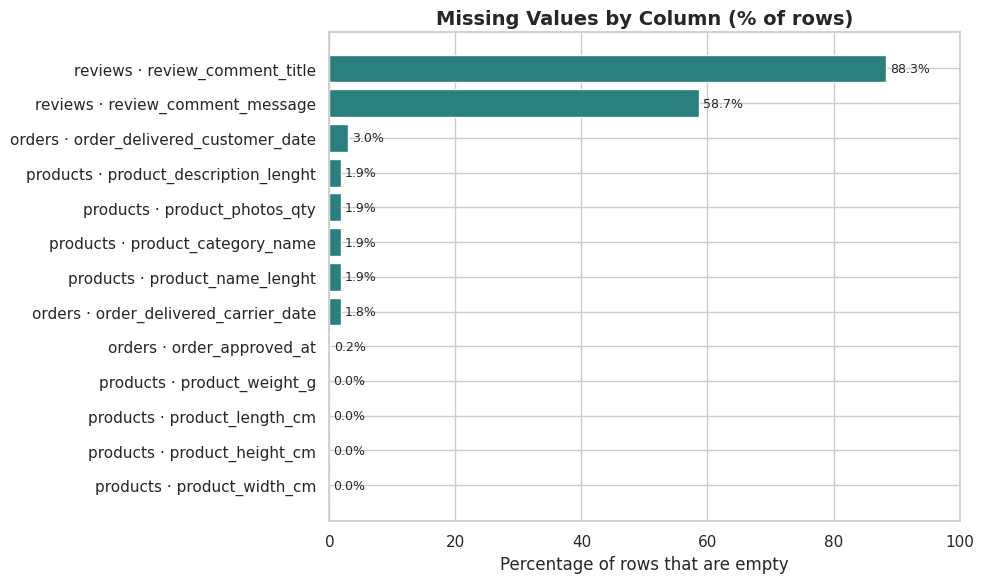

In [7]:
# Visualise the missing-value percentages so the problem areas stand out
plot_df = missing_all.sort_values("missing_pct", ascending=True)
labels = plot_df["table"] + " · " + plot_df["column"]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(labels, plot_df["missing_pct"], color=MAIN)

# Write the exact percentage at the end of each bar
for bar, pct in zip(bars, plot_df["missing_pct"]):
    ax.text(bar.get_width() + 0.6, bar.get_y() + bar.get_height() / 2,
            f"{pct:.1f}%", va="center", fontsize=9)

ax.set_title("Missing Values by Column (% of rows)")
ax.set_xlabel("Percentage of rows that are empty")
ax.set_xlim(0, 100)
plt.tight_layout()
plt.show()

#### Reading the missing-value chart

- `review_comment_title` is empty for roughly 88% of reviews and
  `review_comment_message` for about 59%. This is normal customer behaviour: people tap
  the stars and skip the typing. **These are not errors, so we keep them as they are.**
- The empty delivery timestamps in `orders` are meaningful too. An order that was
  cancelled or is still on the way genuinely has no delivery date. We will simply exclude
  those rows from delivery-speed calculations instead of filling them with fake dates.
- 610 products have no category name. We label them `unknown` rather than deleting them,
  because their sales still count towards total revenue.
- Two products are missing weight and size. We fill those with the median value of the
  column, since two rows out of 32,951 cannot shift the result.

### 5.3 Fixing data types (text ➜ datetime)

Dates stored as text are useless for maths. Converting them lets us subtract one date
from another and get the number of days.

In [8]:
# All the timestamp columns that arrived as plain text
order_date_cols = [
    "order_purchase_timestamp",        # when the customer clicked "buy"
    "order_approved_at",               # when the payment was approved
    "order_delivered_carrier_date",    # when the parcel was handed to the courier
    "order_delivered_customer_date",   # when the customer actually received it
    "order_estimated_delivery_date",   # the date promised at checkout
]

# errors="coerce" turns anything unreadable into NaT instead of crashing
for col in order_date_cols:
    orders_df[col] = pd.to_datetime(orders_df[col], errors="coerce")

items_df["shipping_limit_date"] = pd.to_datetime(items_df["shipping_limit_date"], errors="coerce")
reviews_df["review_creation_date"] = pd.to_datetime(reviews_df["review_creation_date"], errors="coerce")
reviews_df["review_answer_timestamp"] = pd.to_datetime(reviews_df["review_answer_timestamp"], errors="coerce")

print("Date columns converted.\n")
print(orders_df[order_date_cols].dtypes.to_string())

# What time window does this dataset actually cover?
print("\nFirst purchase in the data :", orders_df["order_purchase_timestamp"].min())
print("Last  purchase in the data :", orders_df["order_purchase_timestamp"].max())

Date columns converted.

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]

First purchase in the data : 2016-09-04 21:15:19
Last  purchase in the data : 2018-10-17 17:30:18


### 5.4 Cleaning text and translating product categories

In [9]:
# --- Standardise city names: strip spaces and force lowercase ---
customers_df["customer_city"] = customers_df["customer_city"].str.strip().str.lower()
sellers_df["seller_city"] = sellers_df["seller_city"].str.strip().str.lower()

# --- Translate Portuguese category names into English ---
products_df = products_df.merge(category_df, on="product_category_name", how="left")

# Any product with no category at all is labelled "unknown"
products_df["category"] = products_df["product_category_name_english"].fillna("unknown")

# --- Fix the two products missing weight and size ---
size_cols = ["product_weight_g", "product_length_cm", "product_height_cm", "product_width_cm"]
for col in size_cols:
    products_df[col] = products_df[col].fillna(products_df[col].median())

# --- Fill missing photo counts with 0 (no photo uploaded) ---
products_df["product_photos_qty"] = products_df["product_photos_qty"].fillna(0)

print("Total distinct categories after translation:", products_df["category"].nunique())
print("Products still labelled 'unknown':", (products_df["category"] == "unknown").sum())
print("Remaining missing values in products table:", int(products_df[size_cols].isna().sum().sum()))

Total distinct categories after translation: 72
Products still labelled 'unknown': 623
Remaining missing values in products table: 0


---

## 6. Feature Engineering and the Master Table

### 6.1 Creating new, useful columns

The raw columns alone do not answer business questions. These derived columns do.

In [10]:
# ---------- Delivery timing features ----------

# How many days the parcel actually took, from purchase to hand-over
orders_df["delivery_days"] = (
    orders_df["order_delivered_customer_date"] - orders_df["order_purchase_timestamp"]
).dt.days

# How many days the customer was PROMISED at checkout
orders_df["estimated_days"] = (
    orders_df["order_estimated_delivery_date"] - orders_df["order_purchase_timestamp"]
).dt.days

# Positive value = arrived LATE, negative value = arrived EARLY
orders_df["delay_days"] = (
    orders_df["order_delivered_customer_date"] - orders_df["order_estimated_delivery_date"]
).dt.days

# Simple yes/no flag for a late delivery
orders_df["is_late"] = np.where(orders_df["delay_days"] > 0, 1, 0)

# How long the seller took to hand the parcel to the courier
orders_df["seller_handover_days"] = (
    orders_df["order_delivered_carrier_date"] - orders_df["order_purchase_timestamp"]
).dt.days

# How long the courier took after collecting the parcel
orders_df["carrier_days"] = (
    orders_df["order_delivered_customer_date"] - orders_df["order_delivered_carrier_date"]
).dt.days

# ---------- Calendar features for trend charts ----------
orders_df["order_year"] = orders_df["order_purchase_timestamp"].dt.year
orders_df["order_month"] = orders_df["order_purchase_timestamp"].dt.month
orders_df["order_month_name"] = orders_df["order_purchase_timestamp"].dt.month_name()
orders_df["order_year_month"] = orders_df["order_purchase_timestamp"].dt.to_period("M")
orders_df["order_day_name"] = orders_df["order_purchase_timestamp"].dt.day_name()
orders_df["order_hour"] = orders_df["order_purchase_timestamp"].dt.hour

# ---------- Item level revenue ----------
# Revenue for a line item = product price + the freight charged on it
items_df["item_revenue"] = items_df["price"] + items_df["freight_value"]

orders_df[["order_id", "delivery_days", "estimated_days", "delay_days", "is_late"]].head()

,order_id,delivery_days,estimated_days,delay_days,is_late
0,e481f51cbdc54678b7cc49136f2d6af7,8.00,15,-8.00,0
1,53cdb2fc8bc7dce0b6741e2150273451,13.00,19,-6.00,0
2,47770eb9100c2d0c44946d9cf07ec65d,9.00,26,-18.00,0
3,949d5b44dbf5de918fe9c16f97b45f8a,13.00,26,-13.00,0
4,ad21c59c0840e6cb83a9ceb5573f8159,2.00,12,-10.00,0


### 6.2 Building one master table

Instead of joining tables again and again in every section, we build a single wide table
once and reuse it.

In [11]:
# Start from the item level, because that is where price and freight live,
# then attach order info, then customer, product and seller info.
master_df = (
    items_df
    .merge(orders_df, on="order_id", how="left")
    .merge(customers_df, on="customer_id", how="left")
    .merge(
        products_df[["product_id", "category", "product_weight_g",
                     "product_photos_qty", "product_description_lenght"]],
        on="product_id", how="left"
    )
    .merge(sellers_df[["seller_id", "seller_city", "seller_state"]],
           on="seller_id", how="left")
)

# Flag telling us whether the buyer and the seller are in the same state
master_df["same_state"] = np.where(
    master_df["customer_state"] == master_df["seller_state"], "Same state", "Different state"
)

# For most business questions we only care about completed orders
delivered_df = master_df[master_df["order_status"] == "delivered"].copy()

print("Master table shape        :", master_df.shape)
print("Delivered-only table shape:", delivered_df.shape)
print("Columns available:\n")
print(list(master_df.columns))

Master table shape        : (112650, 38)
Delivered-only table shape: (110197, 38)
Columns available:

['order_id', 'order_item_id', 'product_id', 'seller_id', 'shipping_limit_date', 'price', 'freight_value', 'item_revenue', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'delivery_days', 'estimated_days', 'delay_days', 'is_late', 'seller_handover_days', 'carrier_days', 'order_year', 'order_month', 'order_month_name', 'order_year_month', 'order_day_name', 'order_hour', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state', 'category', 'product_weight_g', 'product_photos_qty', 'product_description_lenght', 'seller_city', 'seller_state', 'same_state']


### 6.3 A one-glance health check of the business

In [12]:
# Pull the headline numbers into a single tidy summary
total_revenue = delivered_df["item_revenue"].sum()
total_orders = delivered_df["order_id"].nunique()
total_customers = customers_df["customer_unique_id"].nunique()
avg_order_value = delivered_df.groupby("order_id")["item_revenue"].sum().mean()

kpi = pd.Series({
    "Total revenue (BRL)": total_revenue,
    "Product revenue (BRL)": delivered_df["price"].sum(),
    "Freight revenue (BRL)": delivered_df["freight_value"].sum(),
    "Delivered orders": total_orders,
    "Unique customers": total_customers,
    "Unique sellers": delivered_df["seller_id"].nunique(),
    "Unique products sold": delivered_df["product_id"].nunique(),
    "Average order value (BRL)": avg_order_value,
    "Average delivery days": delivered_df["delivery_days"].mean(),
    "Late delivery rate (%)": delivered_df["is_late"].mean() * 100,
})

kpi.to_frame("value")

,value
Total revenue (BRL),"15,419,773.75"
Product revenue (BRL),"13,221,498.11"
Freight revenue (BRL),"2,198,275.64"
Delivered orders,"96,478.00"
Unique customers,"96,096.00"
Unique sellers,"2,970.00"
Unique products sold,"32,216.00"
Average order value (BRL),159.83
Average delivery days,12.01
Late delivery rate (%),6.59


#### Headline numbers in plain words

- The marketplace processed roughly **96.5 thousand delivered orders** worth about
  **15.4 million Brazilian reais** in total, once freight is included.
- The **average order comes to around 160 BRL**, which places Olist firmly in the
  low-to-mid ticket range rather than luxury shopping.
- Freight is not a small side item — it makes up close to **17% of what customers pay**
  on top of product price.
- About **3,000 sellers** and **33 thousand distinct products** are active, so this is a
  wide catalogue rather than a deep one.

---

## 7. Exploratory Data Analysis (EDA)

This is the heart of the project. Each sub-section has a chart followed by what the chart
actually means for the business.

### 7.1 Order status — how many orders complete successfully?

              orders  share_pct
order_status                   
delivered      96478      97.02
shipped         1107       1.11
canceled         625       0.63
unavailable      609       0.61
invoiced         314       0.32
processing       301       0.30
created            5       0.01
approved           2       0.00


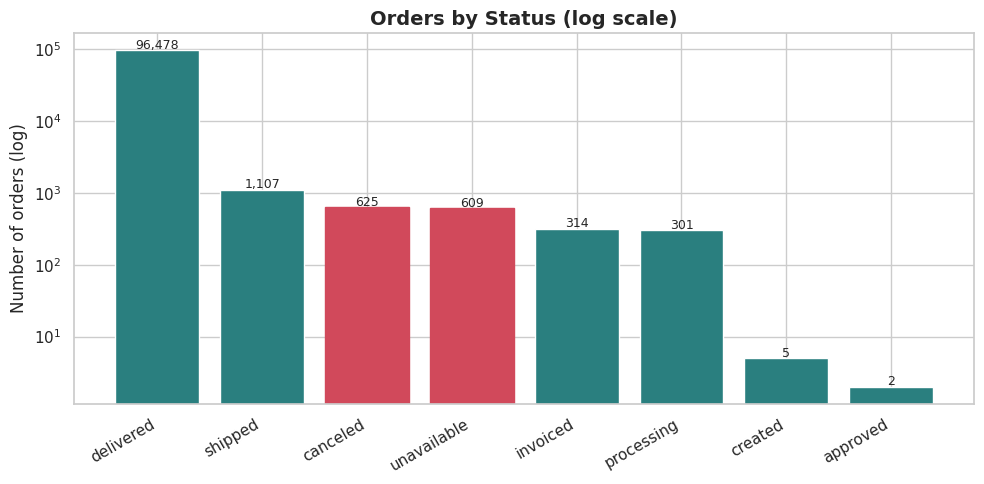

In [13]:
# Count how many orders sit in each status
status_counts = orders_df["order_status"].value_counts()
status_pct = (status_counts / status_counts.sum() * 100).round(2)

status_table = pd.DataFrame({"orders": status_counts, "share_pct": status_pct})
print(status_table.to_string())

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(status_counts.index, status_counts.values, color=MAIN)

# Highlight the problem statuses in red
for bar, name in zip(bars, status_counts.index):
    if name in ("canceled", "unavailable"):
        bar.set_color(ACCENT)

# Put the count on top of each bar
for bar in bars:
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() * 1.05,
            f"{int(bar.get_height()):,}", ha="center", fontsize=9)

ax.set_yscale("log")                      # log scale, otherwise small bars disappear
ax.set_title("Orders by Status (log scale)")
ax.set_ylabel("Number of orders (log)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

#### What the status chart tells us

- Around **97% of all orders end up delivered**, which is a healthy completion rate for a
  marketplace.
- **Cancellations sit near 0.6%** and unavailable items are about the same. Both are small,
  but each one is a customer who paid and then got nothing, so they hurt more than the
  number suggests.
- The tiny counts under `created` and `approved` are simply orders that were still in
  progress on the day the data was exported.

### 7.2 Sales trend over time

Is the business growing month after month?

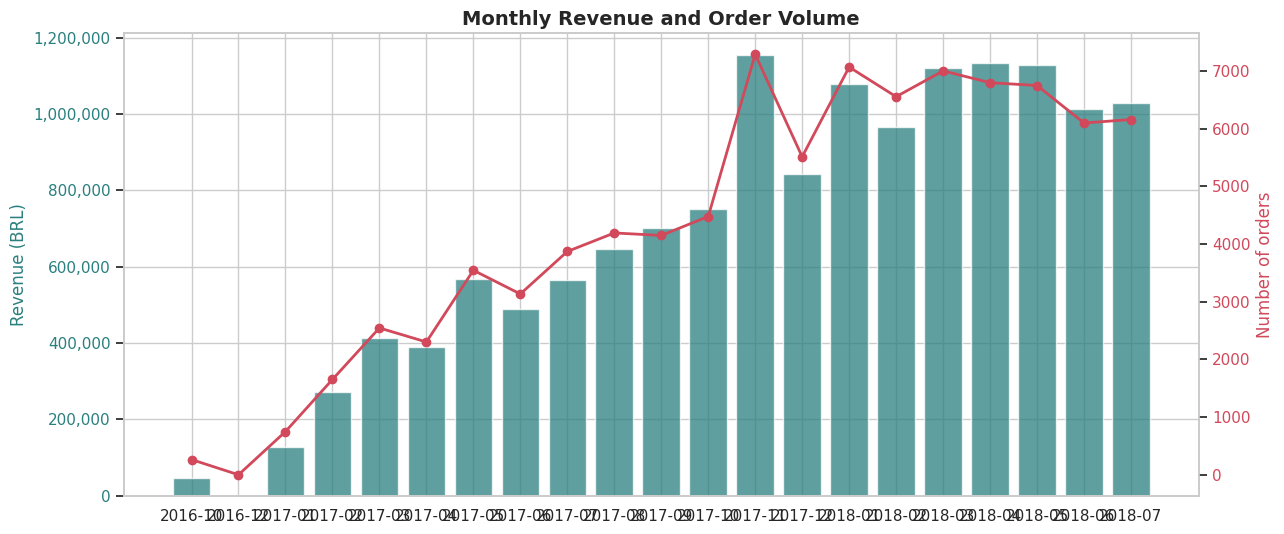

,order_year_month,revenue,orders,revenue_growth_pct
9,2017-08,"645,832.36",4193,14.00
10,2017-09,"701,077.49",4150,8.60
11,2017-10,"751,117.01",4478,7.10
12,2017-11,"1,153,364.20",7289,53.60
13,2017-12,"843,078.29",5513,-26.90
14,2018-01,"1,077,887.46",7069,27.90
15,2018-02,"966,168.41",6555,-10.40
16,2018-03,"1,120,598.24",7003,16.00
17,2018-04,"1,132,878.93",6798,1.10
18,2018-05,"1,128,774.52",6749,-0.40


In [14]:
# Group delivered orders by month
monthly = (
    delivered_df
    .groupby("order_year_month")
    .agg(revenue=("item_revenue", "sum"),
         orders=("order_id", "nunique"))
    .reset_index()
)
monthly["order_year_month"] = monthly["order_year_month"].astype(str)

# Drop the first and last month, because both are only partly recorded
monthly_clean = monthly.iloc[1:-1].reset_index(drop=True)

fig, ax1 = plt.subplots(figsize=(13, 5.5))

# Revenue as bars on the left axis
ax1.bar(monthly_clean["order_year_month"], monthly_clean["revenue"],
        color=MAIN, alpha=0.75, label="Revenue")
ax1.set_ylabel("Revenue (BRL)", color=MAIN)
ax1.tick_params(axis="y", labelcolor=MAIN)
ax1.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

# Order count as a line on the right axis
ax2 = ax1.twinx()
ax2.plot(monthly_clean["order_year_month"], monthly_clean["orders"],
         color=ACCENT, marker="o", linewidth=2, label="Orders")
ax2.set_ylabel("Number of orders", color=ACCENT)
ax2.tick_params(axis="y", labelcolor=ACCENT)
ax2.grid(False)

ax1.set_title("Monthly Revenue and Order Volume")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Month-on-month growth percentage
monthly_clean["revenue_growth_pct"] = monthly_clean["revenue"].pct_change().mul(100).round(1)
monthly_clean.tail(12)

#### Reading the sales trend

- The platform grew **very steeply through 2017**, going from a few hundred thousand reais
  a month to more than a million.
- **November 2017 is the single biggest month**, with revenue jumping roughly 50% above
  October. That spike is Black Friday, which is a major shopping event in Brazil.
- Through **2018 the line flattens out** and hovers around the one-million mark each month.
  Growth has not reversed, but the explosive phase clearly ended.
- The last two months look like a crash on the raw chart. That is **not a real drop** — the
  dataset simply stops mid-collection, which is why we removed those months above. Missing
  this detail is a classic way to reach a wrong conclusion.

#### Business takeaway

- The company moved from a **growth phase into a maturity phase**. Getting the next jump
  will need work on repeat purchases rather than only new-customer acquisition.
- Stock and courier capacity planning should be built around **November**, not around the
  yearly average.

### 7.3 Seasonality — which months, days and hours are busiest?

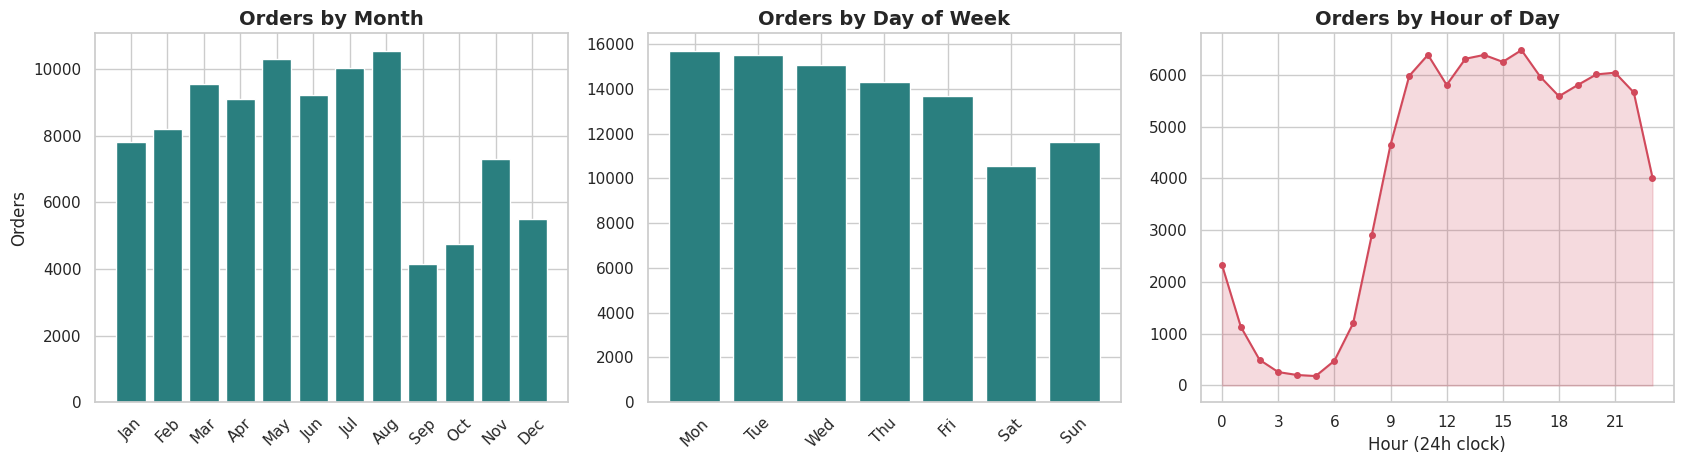

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))

# --- (a) Orders per calendar month, averaged across years ---
month_order = ["January", "February", "March", "April", "May", "June",
               "July", "August", "September", "October", "November", "December"]
by_month = delivered_df.groupby("order_month_name")["order_id"].nunique().reindex(month_order)
axes[0].bar(range(12), by_month.values, color=MAIN)
axes[0].set_xticks(range(12))
axes[0].set_xticklabels([m[:3] for m in month_order], rotation=45)
axes[0].set_title("Orders by Month")
axes[0].set_ylabel("Orders")

# --- (b) Orders per weekday ---
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
by_day = delivered_df.groupby("order_day_name")["order_id"].nunique().reindex(day_order)
axes[1].bar(range(7), by_day.values, color=MAIN)
axes[1].set_xticks(range(7))
axes[1].set_xticklabels([d[:3] for d in day_order], rotation=45)
axes[1].set_title("Orders by Day of Week")

# --- (c) Orders per hour of the day ---
by_hour = delivered_df.groupby("order_hour")["order_id"].nunique()
axes[2].plot(by_hour.index, by_hour.values, color=ACCENT, marker="o", markersize=4)
axes[2].fill_between(by_hour.index, by_hour.values, alpha=0.2, color=ACCENT)
axes[2].set_title("Orders by Hour of Day")
axes[2].set_xlabel("Hour (24h clock)")
axes[2].set_xticks(range(0, 24, 3))

plt.tight_layout()
plt.show()

#### Seasonality insights

- **Monday to Wednesday are the strongest days**, and volume drops steadily towards the
  weekend. Saturday is the quietest day of all — the opposite of what a physical store sees.
- Shopping activity climbs from the morning, peaks in the **late afternoon (roughly 2 PM to
  5 PM)** and stays busy until about 10 PM, then falls away overnight.
- On the monthly view, **May and August are consistently strong**, while September and
  October look weak partly because 2018 data stops early.

#### Practical use

- Send marketing emails and run ad pushes on **Monday to Wednesday, timed for late
  afternoon**, since that is when buying intent is already high.
- Customer-support staffing should be heaviest on weekday afternoons and light on Saturdays.

### 7.4 Product category analysis

#### 7.4.1 Which categories earn the most money?

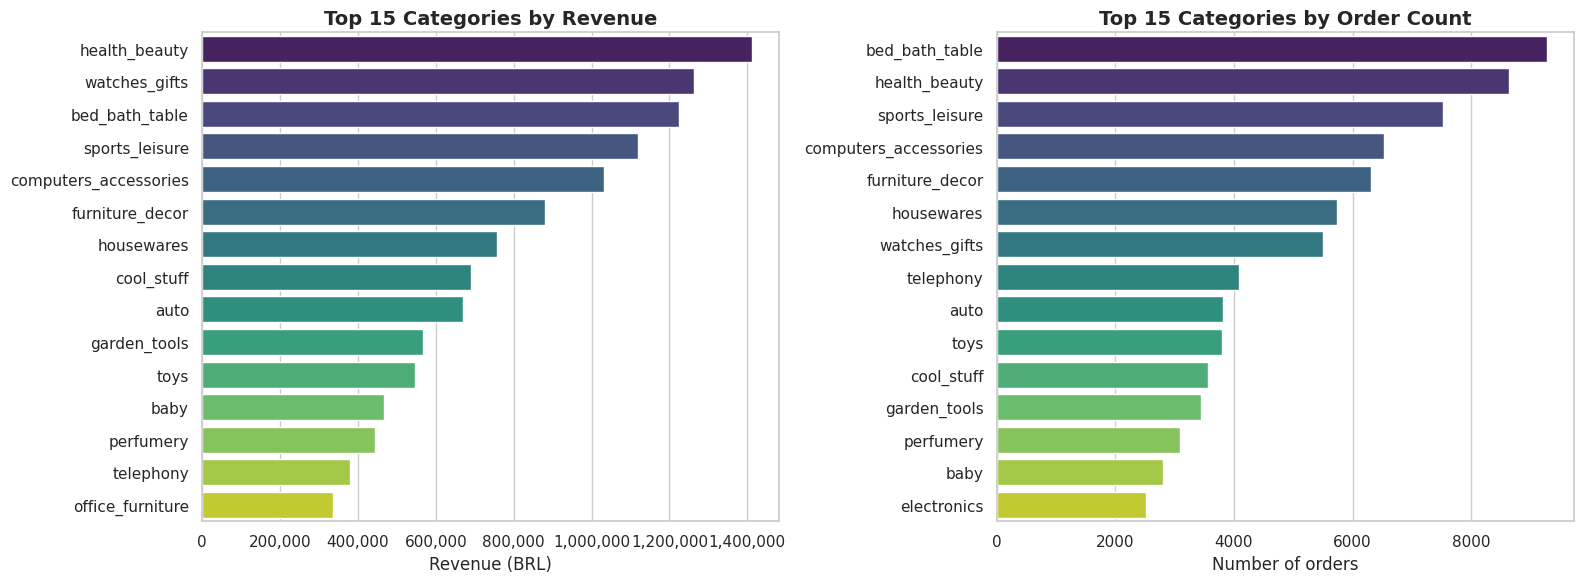

,revenue,orders,avg_price,revenue_share_pct
category,,,,
health_beauty,"1,412,089.53",8647,130.28,9.16
watches_gifts,"1,264,333.12",5495,199.04,8.20
bed_bath_table,"1,225,209.26",9272,93.44,7.95
sports_leisure,"1,118,256.91",7530,113.25,7.25
computers_accessories,"1,032,723.77",6530,116.26,6.70
furniture_decor,"880,329.92",6307,87.25,5.71
housewares,"758,392.25",5743,90.60,4.92
cool_stuff,"691,680.89",3559,164.12,4.49
auto,"669,454.75",3810,139.85,4.34


In [16]:
# Revenue, order count and average price per category
cat_stats = (
    delivered_df
    .groupby("category")
    .agg(revenue=("item_revenue", "sum"),
         orders=("order_id", "nunique"),
         items=("order_item_id", "count"),
         avg_price=("price", "mean"))
    .sort_values("revenue", ascending=False)
)
cat_stats["revenue_share_pct"] = (cat_stats["revenue"] / cat_stats["revenue"].sum() * 100).round(2)

top15 = cat_stats.head(15)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Left: top categories by revenue
sns.barplot(x=top15["revenue"], y=top15.index, hue=top15.index,
            palette=PALETTE, legend=False, ax=axes[0])
axes[0].set_title("Top 15 Categories by Revenue")
axes[0].set_xlabel("Revenue (BRL)")
axes[0].set_ylabel("")
axes[0].xaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

# Right: top categories by number of orders
top15_orders = cat_stats.sort_values("orders", ascending=False).head(15)
sns.barplot(x=top15_orders["orders"], y=top15_orders.index, hue=top15_orders.index,
            palette=PALETTE, legend=False, ax=axes[1])
axes[1].set_title("Top 15 Categories by Order Count")
axes[1].set_xlabel("Number of orders")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

top15[["revenue", "orders", "avg_price", "revenue_share_pct"]]

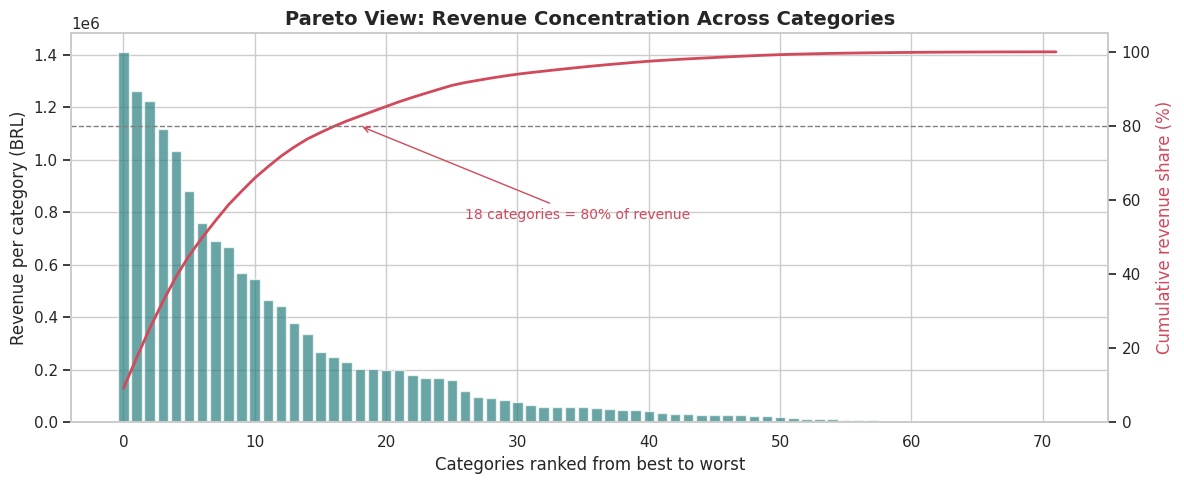

Total categories: 72
Categories needed to reach 80% of revenue: 18


In [17]:
# How concentrated is revenue? Build a Pareto (cumulative share) curve.
pareto = cat_stats["revenue"].sort_values(ascending=False)
cum_share = pareto.cumsum() / pareto.sum() * 100

fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(range(len(pareto)), pareto.values, color=MAIN, alpha=0.7)
ax.set_ylabel("Revenue per category (BRL)")
ax.set_xlabel("Categories ranked from best to worst")

ax2 = ax.twinx()
ax2.plot(range(len(cum_share)), cum_share.values, color=ACCENT, linewidth=2)
ax2.axhline(80, color="grey", linestyle="--", linewidth=1)   # the classic 80% line
ax2.set_ylabel("Cumulative revenue share (%)", color=ACCENT)
ax2.set_ylim(0, 105)
ax2.grid(False)

# How many categories are needed to reach 80% of revenue?
n_for_80 = int((cum_share <= 80).sum() + 1)
ax2.annotate(f"{n_for_80} categories = 80% of revenue",
             xy=(n_for_80, 80), xytext=(n_for_80 + 8, 55),
             arrowprops=dict(arrowstyle="->", color=ACCENT), color=ACCENT, fontsize=10)

ax.set_title("Pareto View: Revenue Concentration Across Categories")
plt.tight_layout()
plt.show()

print(f"Total categories: {len(pareto)}")
print(f"Categories needed to reach 80% of revenue: {n_for_80}")

#### Category insights

- **Health & beauty, watches & gifts, and bed-bath-table** lead on revenue, each bringing in
  well over a million reais.
- Ranking by **number of orders gives a different winner**: bed-bath-table sells the most
  units, while watches & gifts climbs the revenue chart mainly because each item is
  expensive. Comparing the two charts side by side is the whole point here.
- The Pareto curve shows a **clear 80/20 pattern** — a small handful of categories out of
  seventy-odd produce four-fifths of all revenue. The long tail contributes very little
  individually.

#### Business takeaway

- Inventory, advertising budget and courier priority should follow the **top ten
  categories**, since that is where the money genuinely is.
- The tail categories are still worth keeping, because they make the marketplace look
  complete, but they do not deserve premium marketing spend.

#### 7.4.2 Price behaviour across the catalogue

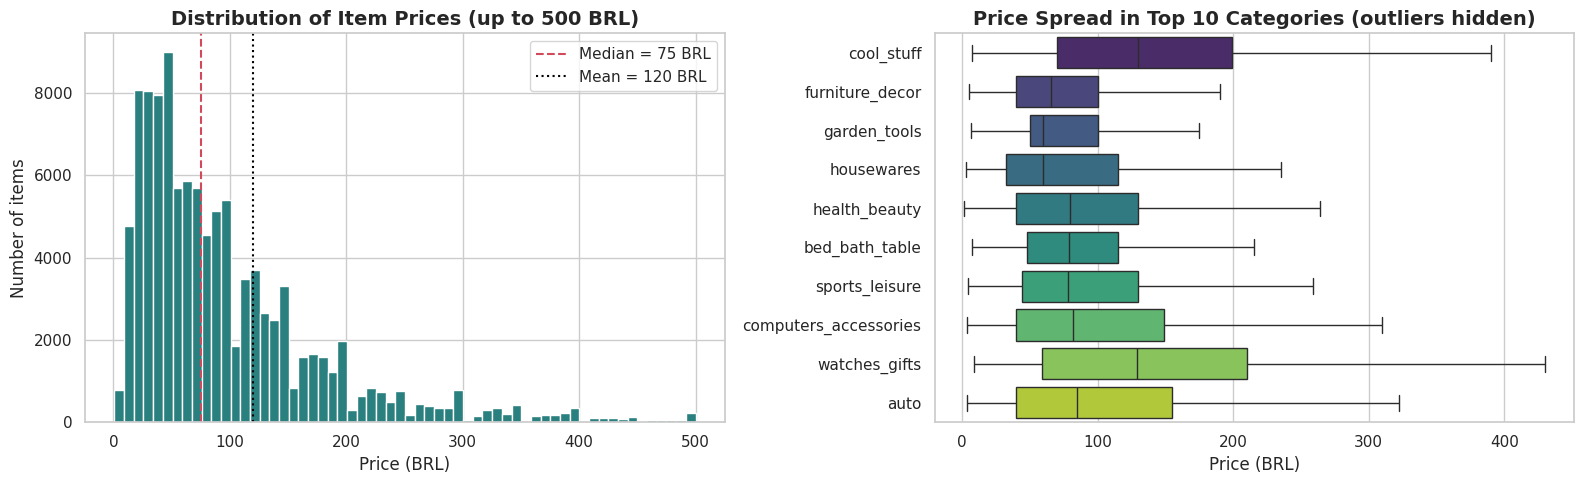

count   110,197.00
mean        119.98
std         182.30
min           0.85
25%          39.90
50%          74.90
75%         134.17
max       6,735.00


In [18]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Left: distribution of item prices, capped at 500 so the chart stays readable
price_capped = delivered_df.loc[delivered_df["price"] <= 500, "price"]
axes[0].hist(price_capped, bins=60, color=MAIN, edgecolor="white")
axes[0].axvline(delivered_df["price"].median(), color=ACCENT, linestyle="--",
                label=f"Median = {delivered_df['price'].median():,.0f} BRL")
axes[0].axvline(delivered_df["price"].mean(), color="black", linestyle=":",
                label=f"Mean = {delivered_df['price'].mean():,.0f} BRL")
axes[0].set_title("Distribution of Item Prices (up to 500 BRL)")
axes[0].set_xlabel("Price (BRL)")
axes[0].set_ylabel("Number of items")
axes[0].legend()

# Right: price spread of the 10 biggest categories
top10_cats = cat_stats.head(10).index
box_data = delivered_df[delivered_df["category"].isin(top10_cats)]
sns.boxplot(data=box_data, x="price", y="category", hue="category",
            palette=PALETTE, legend=False, showfliers=False, ax=axes[1])
axes[1].set_title("Price Spread in Top 10 Categories (outliers hidden)")
axes[1].set_xlabel("Price (BRL)")
axes[1].set_ylabel("")

plt.tight_layout()
plt.show()

print(delivered_df["price"].describe().to_string())

#### Price insights

- Prices are **heavily skewed to the right**: most items cost under 100 BRL, but a small
  number of expensive products drag the average up. The mean sits near 120 BRL while the
  median is only about 75 BRL — whenever the mean is much larger than the median, you are
  looking at a skewed distribution.
- **Watches & gifts and computer accessories** carry visibly higher price boxes, while
  bed-bath-table and housewares sit at the cheaper end.
- For any pricing decision on this catalogue, the **median is the safer number to quote**,
  because the mean is inflated by a handful of premium products.

### 7.5 Geographic analysis — where do the customers live?

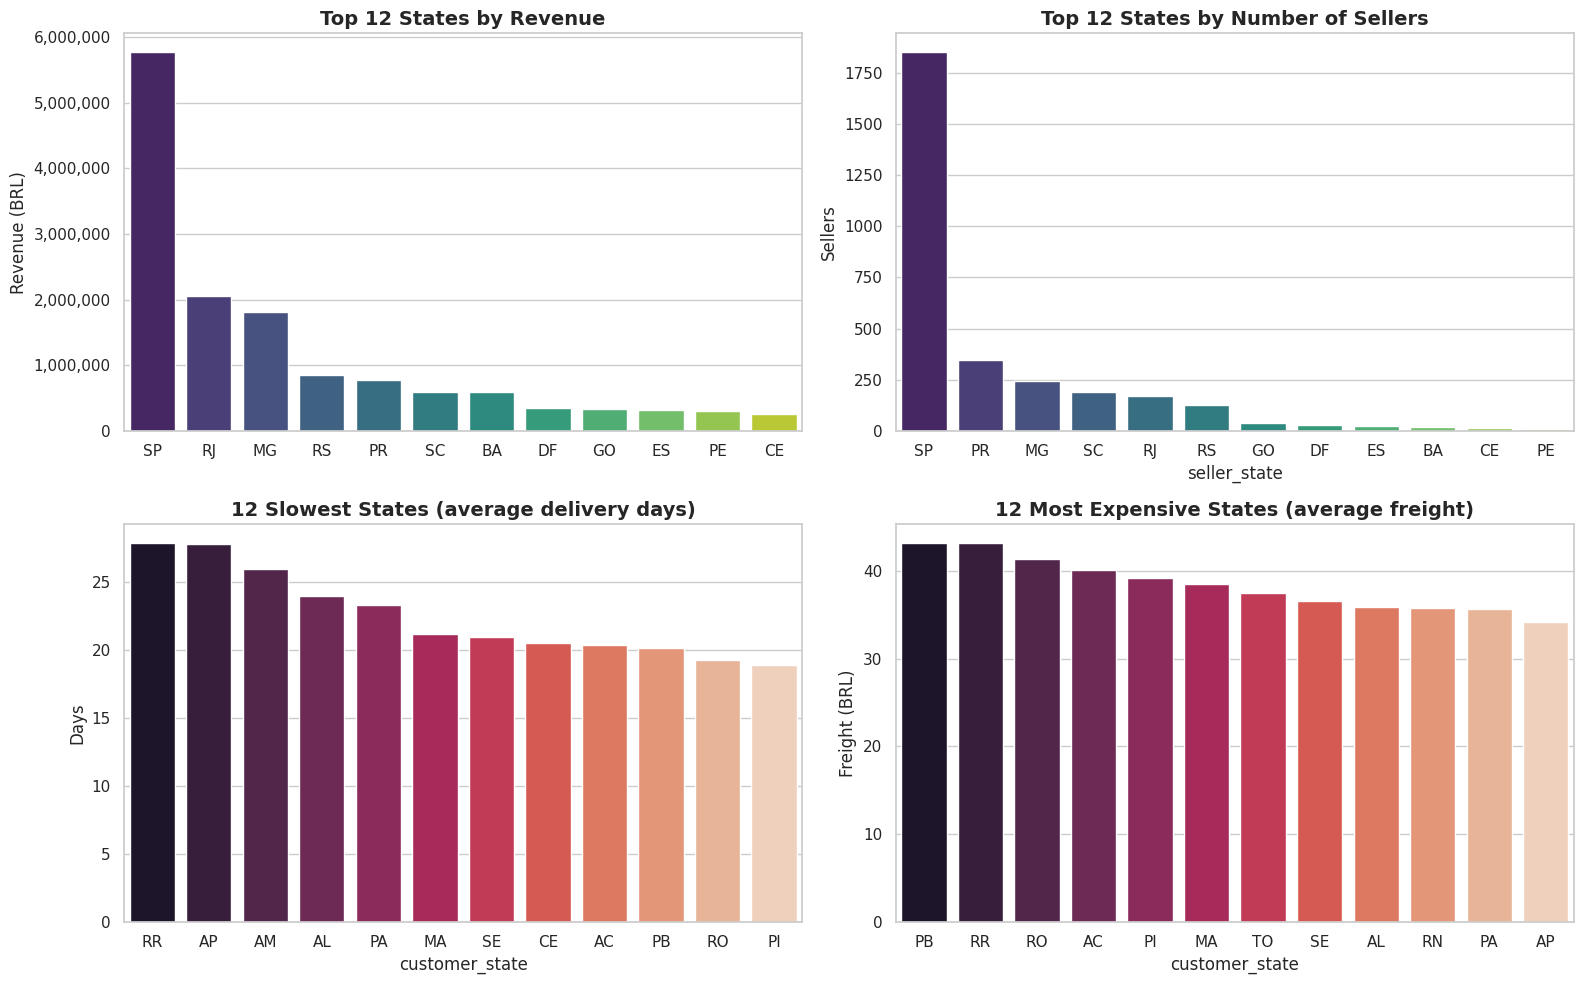

,orders,revenue,avg_freight,avg_delivery_days,revenue_share_pct
customer_state,,,,,
SP,40501,"5,769,703.15",15.12,8.26,37.42
RJ,12350,"2,055,401.57",20.91,14.69,13.33
MG,11354,"1,818,891.67",20.63,11.51,11.80
RS,5345,"861,472.79",21.61,14.71,5.59
PR,4923,"781,708.80",20.47,11.48,5.07
SC,3546,"595,127.78",21.51,14.52,3.86
BA,3256,"591,137.81",26.49,18.77,3.83
DF,2080,"346,123.35",21.07,12.50,2.24
GO,1957,"334,212.35",22.56,14.95,2.17


In [19]:
# Customer-side view by state
state_stats = (
    delivered_df
    .groupby("customer_state")
    .agg(orders=("order_id", "nunique"),
         revenue=("item_revenue", "sum"),
         avg_freight=("freight_value", "mean"),
         avg_delivery_days=("delivery_days", "mean"))
    .sort_values("revenue", ascending=False)
)
state_stats["revenue_share_pct"] = (state_stats["revenue"] / state_stats["revenue"].sum() * 100).round(2)

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# (a) Revenue by state
top_states = state_stats.head(12)
sns.barplot(x=top_states.index, y=top_states["revenue"], hue=top_states.index,
            palette=PALETTE, legend=False, ax=axes[0, 0])
axes[0, 0].set_title("Top 12 States by Revenue")
axes[0, 0].set_ylabel("Revenue (BRL)")
axes[0, 0].set_xlabel("")
axes[0, 0].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

# (b) Where the sellers are based
seller_states = sellers_df["seller_state"].value_counts().head(12)
sns.barplot(x=seller_states.index, y=seller_states.values, hue=seller_states.index,
            palette=PALETTE, legend=False, ax=axes[0, 1])
axes[0, 1].set_title("Top 12 States by Number of Sellers")
axes[0, 1].set_ylabel("Sellers")

# (c) Average delivery time per state, slowest first
slow = state_stats.sort_values("avg_delivery_days", ascending=False).head(12)
sns.barplot(x=slow.index, y=slow["avg_delivery_days"], hue=slow.index,
            palette="rocket", legend=False, ax=axes[1, 0])
axes[1, 0].set_title("12 Slowest States (average delivery days)")
axes[1, 0].set_ylabel("Days")

# (d) Average freight cost per state, most expensive first
costly = state_stats.sort_values("avg_freight", ascending=False).head(12)
sns.barplot(x=costly.index, y=costly["avg_freight"], hue=costly.index,
            palette="rocket", legend=False, ax=axes[1, 1])
axes[1, 1].set_title("12 Most Expensive States (average freight)")
axes[1, 1].set_ylabel("Freight (BRL)")

plt.tight_layout()
plt.show()

state_stats.head(10)

In [20]:
# Does buying from a seller in another state slow things down?
same_state_stats = (
    delivered_df
    .groupby("same_state")
    .agg(orders=("order_id", "nunique"),
         avg_delivery_days=("delivery_days", "mean"),
         avg_freight=("freight_value", "mean"),
         late_rate_pct=("is_late", lambda s: s.mean() * 100))
)
same_state_stats.round(2)

,orders,avg_delivery_days,avg_freight,late_rate_pct
same_state,,,,
Different state,61898,14.58,23.63,7.81
Same state,34827,7.46,13.45,4.45


#### Geography insights

- **São Paulo (SP) alone accounts for about 42% of all orders** and a similar slice of
  revenue. Rio de Janeiro and Minas Gerais follow, and together the top three states carry
  well over half the marketplace.
- The sellers are concentrated in the **same place as the buyers** — roughly 60% of all
  sellers are registered in SP. That is why deliveries inside the south-east are quick.
- The northern states tell the opposite story: **average delivery there stretches past
  20 days and freight costs the most**, because parcels have to cross very long distances
  from the south-eastern warehouses.
- Orders where buyer and seller sit in the **same state arrive noticeably faster and cheaper**
  than cross-state orders.

#### Business takeaway

- Depending this heavily on one state is a **concentration risk**. A courier strike or
  regional problem in SP would hit almost half the business at once.
- Recruiting sellers or opening a small fulfilment point in the **north and north-east**
  would cut both delivery time and freight cost, which are exactly the two things that drive
  bad reviews (shown in section 7.8).

### 7.6 Payment behaviour

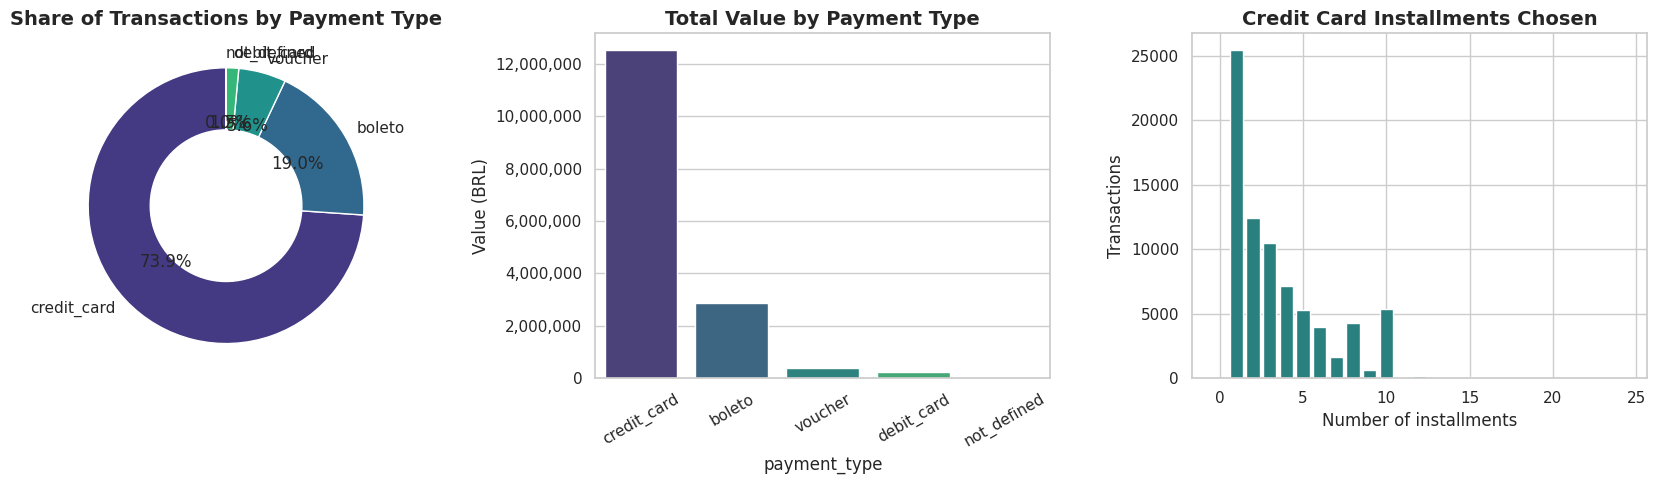

,transactions,avg_value
payment_installments,,
0,2,94.32
1,25455,95.87
2,12413,127.23
3,10461,142.54
4,7098,163.98
5,5239,183.47
6,3920,209.85
7,1626,187.67
8,4268,307.74


In [21]:
# Payment type shares
pay_type = payments_df["payment_type"].value_counts()
pay_value = payments_df.groupby("payment_type")["payment_value"].sum().sort_values(ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# (a) Share of transactions by payment method
axes[0].pie(pay_type.values, labels=pay_type.index, autopct="%1.1f%%",
            colors=sns.color_palette(PALETTE, len(pay_type)), startangle=90,
            wedgeprops=dict(width=0.45))          # donut style
axes[0].set_title("Share of Transactions by Payment Type")

# (b) Total value processed per payment method
sns.barplot(x=pay_value.index, y=pay_value.values, hue=pay_value.index,
            palette=PALETTE, legend=False, ax=axes[1])
axes[1].set_title("Total Value by Payment Type")
axes[1].set_ylabel("Value (BRL)")
axes[1].tick_params(axis="x", rotation=30)
axes[1].yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))

# (c) How many installments people choose on credit cards
inst = payments_df.loc[payments_df["payment_type"] == "credit_card", "payment_installments"]
inst_counts = inst.value_counts().sort_index()
axes[2].bar(inst_counts.index, inst_counts.values, color=MAIN)
axes[2].set_title("Credit Card Installments Chosen")
axes[2].set_xlabel("Number of installments")
axes[2].set_ylabel("Transactions")

plt.tight_layout()
plt.show()

# Does paying in more installments go with a bigger basket?
inst_value = (
    payments_df[payments_df["payment_type"] == "credit_card"]
    .groupby("payment_installments")
    .agg(transactions=("payment_value", "count"),
         avg_value=("payment_value", "mean"))
    .head(13)
)
inst_value.round(2)

#### Payment insights

- **Credit card is the dominant method**, used in roughly three out of four transactions.
  *Boleto* — a Brazilian bank slip paid offline — comes second at about 19%, which is a
  local habit you will not see in most other countries.
- Debit cards and vouchers barely register, so the payment page should be built around
  cards and boleto first.
- About **two-thirds of card users split the payment into installments**, and the average
  is around 3.5. Instalment count rises together with the order value, which strongly
  suggests customers use EMI to make a larger basket feel affordable.

#### Business takeaway

- Instalments are not a nice-to-have here, they are a **sales driver**. Removing or
  restricting them would likely shrink average order value.
- Boleto orders are worth watching separately, because they get approved only after the
  customer walks to a bank or pays online, which adds delay before shipping even starts.

### 7.7 Delivery performance — the operational heartbeat

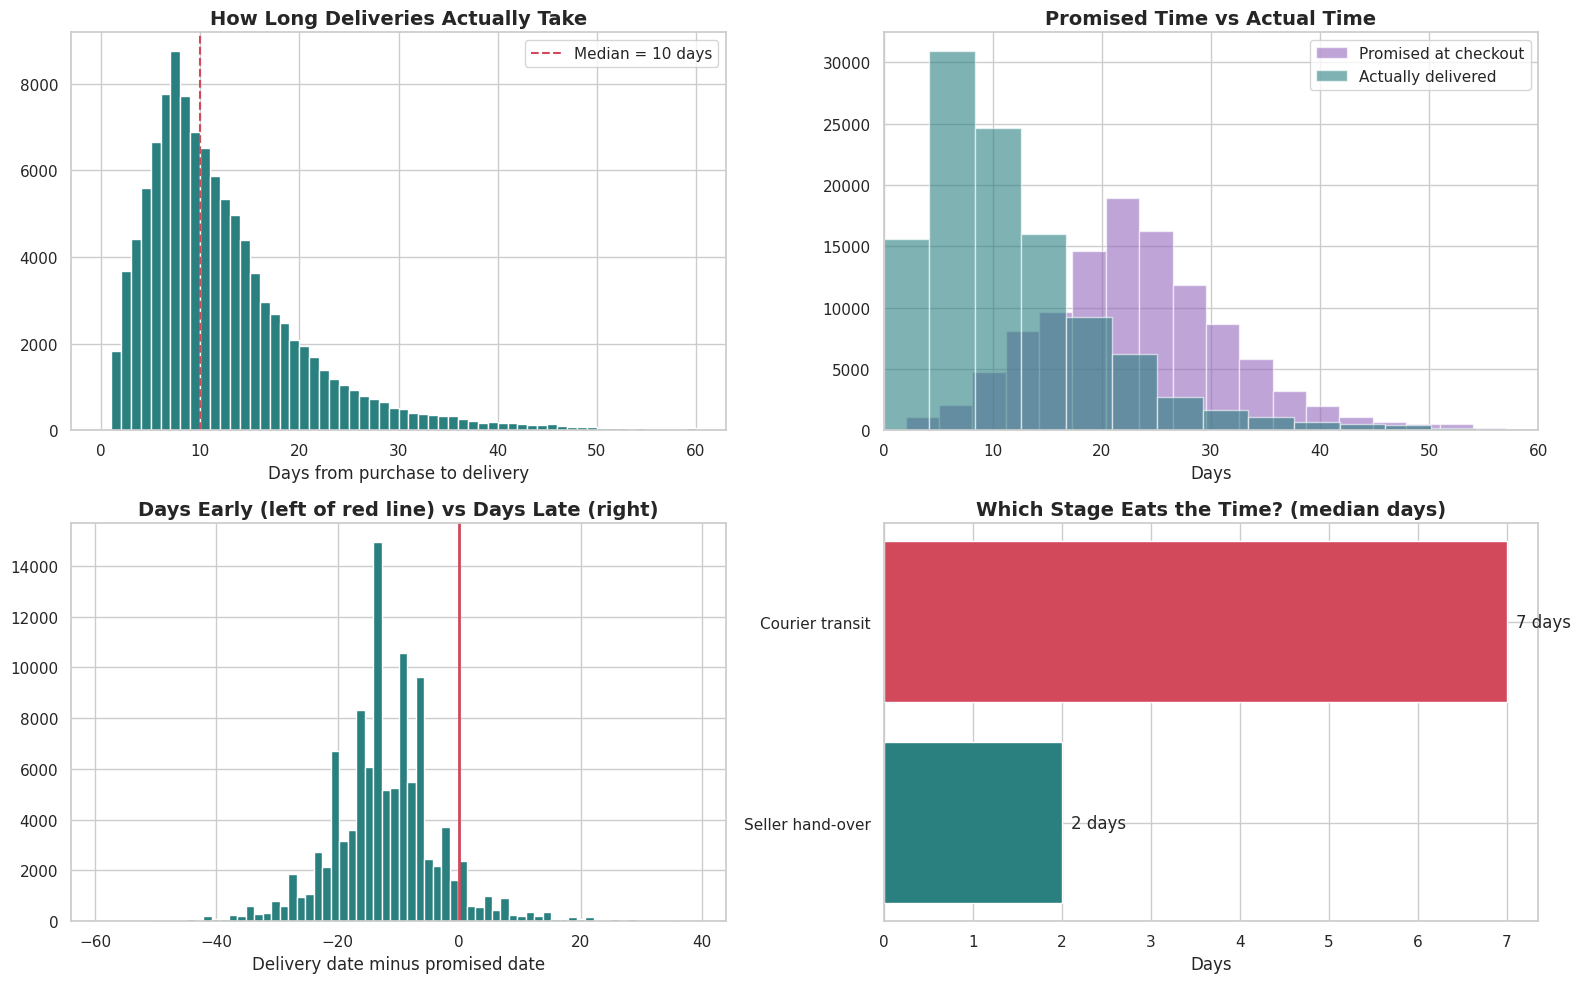

Average actual delivery time : 12.01 days
Average promised time        : 23.44 days
Orders delivered late        : 6.59 %
Average days finished early  : 12.03 days


In [22]:
# Work only with orders that were actually delivered and have a valid duration
dd = delivered_df.dropna(subset=["delivery_days"])

fig, axes = plt.subplots(2, 2, figsize=(16, 10))

# (a) Distribution of actual delivery time
axes[0, 0].hist(dd.loc[dd["delivery_days"] <= 60, "delivery_days"], bins=60,
                color=MAIN, edgecolor="white")
axes[0, 0].axvline(dd["delivery_days"].median(), color=ACCENT, linestyle="--",
                   label=f"Median = {dd['delivery_days'].median():.0f} days")
axes[0, 0].set_title("How Long Deliveries Actually Take")
axes[0, 0].set_xlabel("Days from purchase to delivery")
axes[0, 0].legend()

# (b) Promised vs actual
axes[0, 1].hist(dd["estimated_days"].dropna(), bins=50, alpha=0.6,
                label="Promised at checkout", color="#9467bd")
axes[0, 1].hist(dd["delivery_days"], bins=50, alpha=0.6,
                label="Actually delivered", color=MAIN)
axes[0, 1].set_xlim(0, 60)
axes[0, 1].set_title("Promised Time vs Actual Time")
axes[0, 1].set_xlabel("Days")
axes[0, 1].legend()

# (c) Early or late? Negative means the parcel beat the promise.
delay = dd["delay_days"].dropna()
delay_plot = delay[(delay > -60) & (delay < 40)]
axes[1, 0].hist(delay_plot, bins=70, color=MAIN, edgecolor="white")
axes[1, 0].axvline(0, color=ACCENT, linewidth=2)
axes[1, 0].set_title("Days Early (left of red line) vs Days Late (right)")
axes[1, 0].set_xlabel("Delivery date minus promised date")

# (d) Where the time actually goes: seller side vs courier side
stage = pd.DataFrame({
    "Seller hand-over": dd["seller_handover_days"].median(),
    "Courier transit": dd["carrier_days"].median(),
}, index=["Median days"]).T
axes[1, 1].barh(stage.index, stage["Median days"], color=[MAIN, ACCENT])
for i, v in enumerate(stage["Median days"]):
    axes[1, 1].text(v + 0.1, i, f"{v:.0f} days", va="center")
axes[1, 1].set_title("Which Stage Eats the Time? (median days)")
axes[1, 1].set_xlabel("Days")

plt.tight_layout()
plt.show()

print("Average actual delivery time :", round(dd["delivery_days"].mean(), 2), "days")
print("Average promised time        :", round(dd["estimated_days"].mean(), 2), "days")
print("Orders delivered late        :", round(dd["is_late"].mean() * 100, 2), "%")
print("Average days finished early  :", round(-dd["delay_days"].mean(), 2), "days")

#### Delivery insights

- The **typical delivery takes about 10 days** and the average is 12, with a long tail of
  orders that drag on for a month or more.
- The date shown at checkout averages **around 23 days**, which is roughly double the real
  time. In other words the platform **deliberately under-promises**.
- Because of that cushion, only **about 6.6% of orders arrive late**, and the average parcel
  turns up **12 days ahead of the promised date**.
- Splitting the journey into two stages shows that most of the clock is spent in
  **courier transit**, not with the seller. Sellers usually hand the parcel over within a
  couple of days.

#### Business takeaway

- Under-promising protects the review score, but a 23-day quote may also **scare off buyers
  at checkout**. There is room to tighten the promise in the south-east, where actual
  performance is much faster, while keeping the long buffer for distant states.
- Since the bottleneck is transit rather than the seller, improvement work should focus on
  **courier partnerships and regional hubs**, not on pressuring sellers to ship faster.

### 7.8 Reviews and customer satisfaction

#### 7.8.1 What do the ratings look like overall?

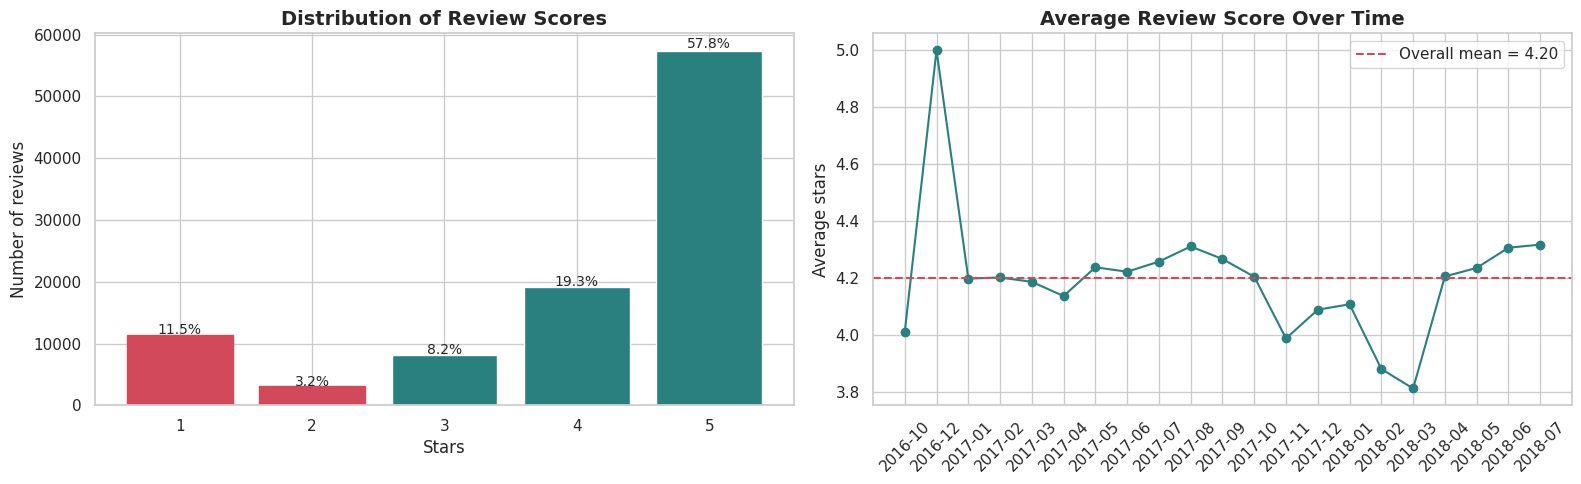

In [23]:
# Merge review scores onto order-level delivery facts
order_level = (
    delivered_df
    .groupby("order_id")
    .agg(delivery_days=("delivery_days", "first"),
         delay_days=("delay_days", "first"),
         is_late=("is_late", "first"),
         order_value=("item_revenue", "sum"),
         freight=("freight_value", "sum"),
         state=("customer_state", "first"),
         category=("category", "first"))
    .reset_index()
)

# One order can technically have more than one review row, so average them first
review_by_order = reviews_df.groupby("order_id")["review_score"].mean().reset_index()
order_level = order_level.merge(review_by_order, on="order_id", how="inner")

score_dist = reviews_df["review_score"].value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

bars = axes[0].bar(score_dist.index, score_dist.values, color=MAIN)
for bar in bars[:2]:
    bar.set_color(ACCENT)                       # colour 1 and 2 stars red
for bar, val in zip(bars, score_dist.values):
    pct = val / score_dist.sum() * 100
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() * 1.01,
                 f"{pct:.1f}%", ha="center", fontsize=10)
axes[0].set_title("Distribution of Review Scores")
axes[0].set_xlabel("Stars")
axes[0].set_ylabel("Number of reviews")

# Average score month by month, to see whether service is improving
rev_trend = (
    delivered_df[["order_id", "order_year_month"]].drop_duplicates()
    .merge(review_by_order, on="order_id")
    .groupby("order_year_month")["review_score"].mean()
)
rev_trend.index = rev_trend.index.astype(str)
rev_trend = rev_trend.iloc[1:-1]                # trim the incomplete edge months
axes[1].plot(rev_trend.index, rev_trend.values, marker="o", color=MAIN)
axes[1].axhline(rev_trend.mean(), color=ACCENT, linestyle="--",
                label=f"Overall mean = {rev_trend.mean():.2f}")
axes[1].set_title("Average Review Score Over Time")
axes[1].set_ylabel("Average stars")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()

plt.tight_layout()
plt.show()

#### 7.8.2 Does slow delivery really destroy the rating?

This is the single most valuable question in the dataset, so it gets its own analysis.

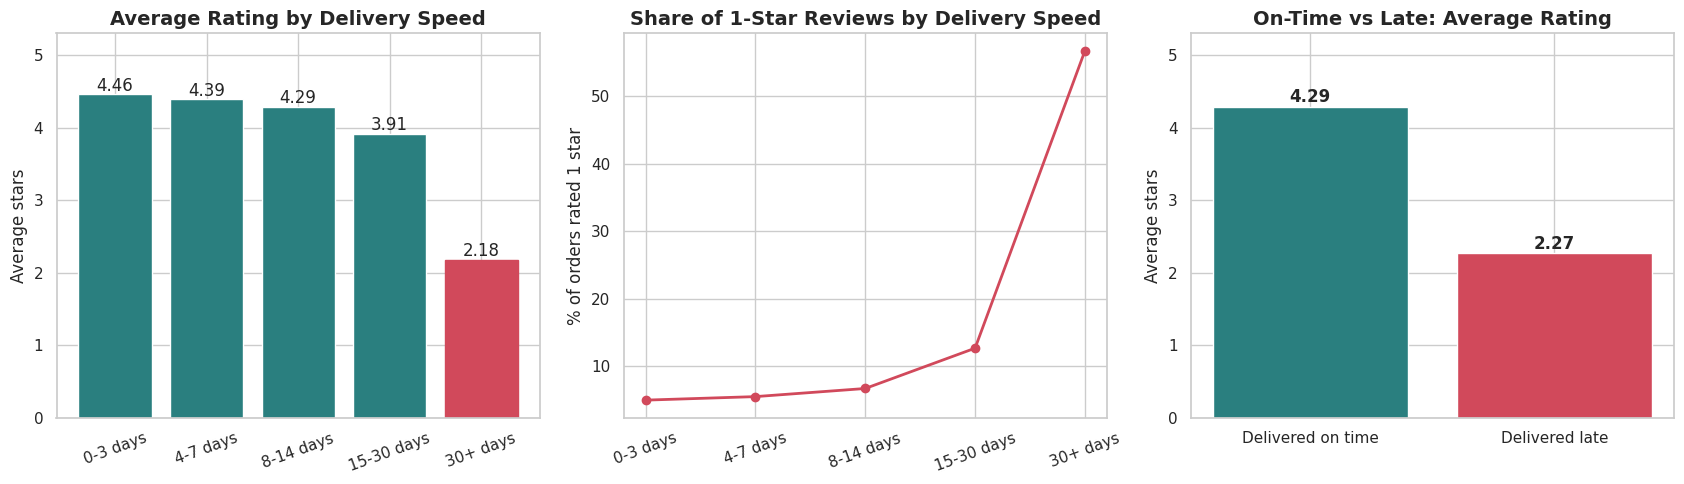

                 avg_score  orders  pct_1_star
delivery_bucket                               
0-3 days              4.46    8565        5.00
4-7 days              4.39   24974        5.52
8-14 days             4.29   36190        6.72
15-30 days            3.91   22088       12.69
30+ days              2.18    4007       56.70

Correlation between delivery days and review score: -0.334


In [24]:
# Bucket orders by how long delivery took, then look at the average score in each bucket
bins = [-1, 3, 7, 14, 30, 1000]
labels = ["0-3 days", "4-7 days", "8-14 days", "15-30 days", "30+ days"]
order_level["delivery_bucket"] = pd.cut(order_level["delivery_days"], bins=bins, labels=labels)

bucket_scores = (
    order_level
    .groupby("delivery_bucket", observed=True)
    .agg(avg_score=("review_score", "mean"),
         orders=("order_id", "count"),
         pct_1_star=("review_score", lambda s: (s == 1).mean() * 100))
)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# (a) Average score by delivery speed
bars = axes[0].bar(bucket_scores.index.astype(str), bucket_scores["avg_score"], color=MAIN)
bars[-1].set_color(ACCENT)
for bar, v in zip(bars, bucket_scores["avg_score"]):
    axes[0].text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.05,
                 f"{v:.2f}", ha="center")
axes[0].set_ylim(0, 5.3)
axes[0].set_title("Average Rating by Delivery Speed")
axes[0].set_ylabel("Average stars")
axes[0].tick_params(axis="x", rotation=20)

# (b) Share of 1-star reviews by delivery speed
axes[1].plot(bucket_scores.index.astype(str), bucket_scores["pct_1_star"],
             marker="o", color=ACCENT, linewidth=2)
axes[1].set_title("Share of 1-Star Reviews by Delivery Speed")
axes[1].set_ylabel("% of orders rated 1 star")
axes[1].tick_params(axis="x", rotation=20)

# (c) On-time versus late orders
late_cmp = order_level.groupby("is_late")["review_score"].mean()
axes[2].bar(["Delivered on time", "Delivered late"], late_cmp.values, color=[MAIN, ACCENT])
for i, v in enumerate(late_cmp.values):
    axes[2].text(i, v + 0.06, f"{v:.2f}", ha="center", fontsize=12, fontweight="bold")
axes[2].set_ylim(0, 5.3)
axes[2].set_title("On-Time vs Late: Average Rating")
axes[2].set_ylabel("Average stars")

plt.tight_layout()
plt.show()

print(bucket_scores.round(2).to_string())
print("\nCorrelation between delivery days and review score:",
      round(order_level["delivery_days"].corr(order_level["review_score"]), 3))

#### Review insights — the clearest finding in the whole project

- Ratings are **top-heavy**: about 58% of customers give 5 stars and roughly 77% give 4 or
  5. But **1-star reviews are the second most common score** at around 12%, so this is a
  love-it-or-hate-it pattern rather than a bell curve.
- Delivery speed and rating move together in a very clean way. Orders arriving within
  three days average about **4.5 stars**, while orders taking more than a month collapse to
  roughly **2.2 stars**.
- Comparing promise to reality is even sharper: an order that arrives on time averages
  around **4.3 stars**, and a late order averages about **2.3 stars**. **Being late costs
  roughly two full stars.**
- The correlation between delivery days and score is about **-0.33** — negative, as expected,
  and strong enough to matter. It is not -0.9 because plenty of other things also annoy
  customers, such as a damaged or wrong product.

#### Business takeaway

- **Logistics is the customer-satisfaction lever on this platform.** Fixing the slowest tail
  of deliveries would lift the average rating more than any change to product pages or
  pricing.
- The safest quick win is to protect the promised date. Since late delivery is what really
  hurts, the buffer strategy works — but it must hold up in the distant states too.

### 7.9 Seller performance

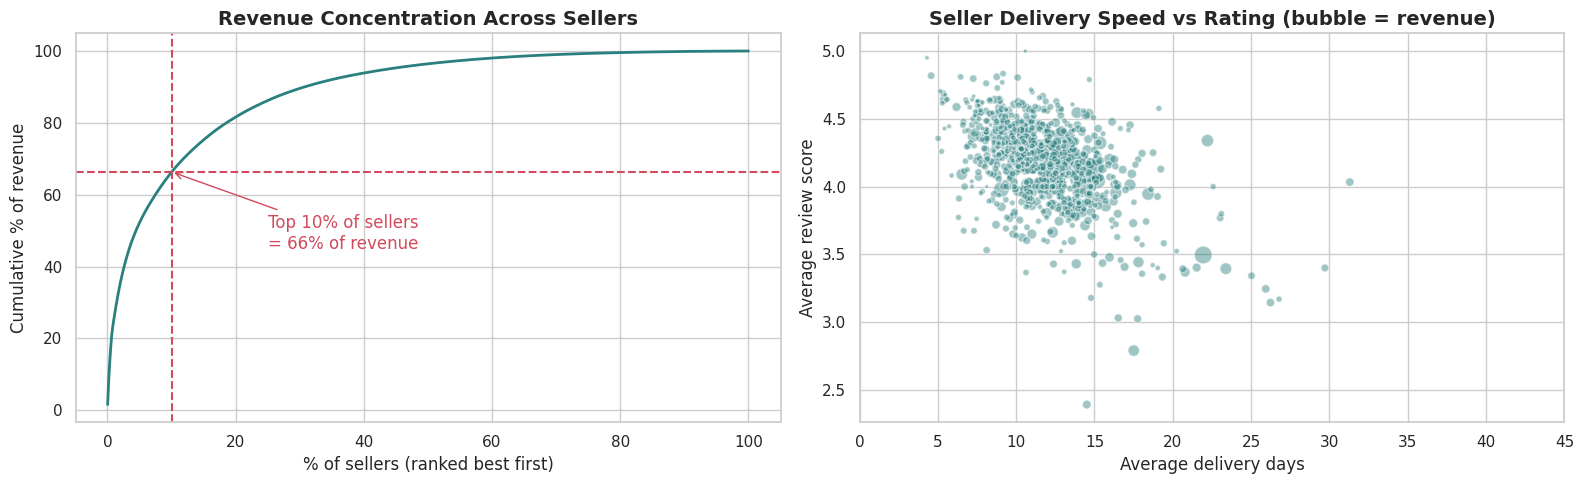

Total active sellers: 2970
Top 10% of sellers hold 66.4% of revenue

Top 10 sellers:


,revenue,orders,items,avg_delivery_days,state,review_score
seller_id,,,,,,
4869f7a5dfa277a7dca6462dcf3b52b2,"247,007.06",1124,1148,14.55,SP,4.15
7c67e1448b00f6e969d365cea6b010ab,"237,806.69",973,1355,21.95,SP,3.50
4a3ca9315b744ce9f8e9374361493884,"231,220.43",1772,1949,13.94,SP,3.85
53243585a1d6dc2643021fd1853d8905,"230,797.02",348,400,12.94,BA,4.19
fa1c13f2614d7b5c4749cbc52fecda94,"200,833.50",578,579,12.84,SP,4.37
da8622b14eb17ae2831f4ac5b9dab84a,"184,706.78",1311,1548,10.70,SP,4.18
7e93a43ef30c4f03f38b393420bc753a,"171,973.55",319,322,10.83,SP,4.36
1025f0e2d44d7041d6cf58b6550e0bfa,"171,924.96",910,1420,11.57,SP,4.01
7a67c85e85bb2ce8582c35f2203ad736,"160,278.52",1145,1155,10.69,SP,4.27


In [25]:
# Build one row per seller
seller_perf = (
    delivered_df
    .groupby("seller_id")
    .agg(revenue=("item_revenue", "sum"),
         orders=("order_id", "nunique"),
         items=("order_item_id", "count"),
         avg_delivery_days=("delivery_days", "mean"),
         state=("seller_state", "first"))
    .sort_values("revenue", ascending=False)
)

# Attach the average review score each seller receives
seller_reviews = (
    delivered_df[["order_id", "seller_id"]].drop_duplicates()
    .merge(review_by_order, on="order_id")
    .groupby("seller_id")["review_score"].mean()
)
seller_perf = seller_perf.join(seller_reviews)

# Revenue concentration: what share do the biggest sellers hold?
rev_sorted = seller_perf["revenue"].sort_values(ascending=False)
cum = rev_sorted.cumsum() / rev_sorted.sum() * 100
top10pct = int(len(rev_sorted) * 0.10)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# (a) Cumulative revenue curve across sellers
axes[0].plot(np.arange(1, len(cum) + 1) / len(cum) * 100, cum.values, color=MAIN, linewidth=2)
axes[0].axvline(10, color=ACCENT, linestyle="--")
axes[0].axhline(cum.iloc[top10pct], color=ACCENT, linestyle="--")
axes[0].set_title("Revenue Concentration Across Sellers")
axes[0].set_xlabel("% of sellers (ranked best first)")
axes[0].set_ylabel("Cumulative % of revenue")
axes[0].annotate(f"Top 10% of sellers\n= {cum.iloc[top10pct]:.0f}% of revenue",
                 xy=(10, cum.iloc[top10pct]), xytext=(25, 45),
                 arrowprops=dict(arrowstyle="->", color=ACCENT), color=ACCENT)

# (b) Do big sellers deliver better? Only sellers with 20+ orders are compared.
active = seller_perf[seller_perf["orders"] >= 20]
axes[1].scatter(active["avg_delivery_days"], active["review_score"],
                s=np.sqrt(active["revenue"]) / 3, alpha=0.45, color=MAIN, edgecolor="white")
axes[1].set_title("Seller Delivery Speed vs Rating (bubble = revenue)")
axes[1].set_xlabel("Average delivery days")
axes[1].set_ylabel("Average review score")
axes[1].set_xlim(0, 45)

plt.tight_layout()
plt.show()

print("Total active sellers:", len(seller_perf))
print(f"Top 10% of sellers hold {cum.iloc[top10pct]:.1f}% of revenue")
print("\nTop 10 sellers:")
seller_perf.head(10).round(2)

#### Seller insights

- Around **3,000 sellers** are active, but the revenue split is very uneven: the
  **top 10% bring in about two-thirds of all revenue**. This is an even harsher Pareto
  pattern than we saw with categories.
- The scatter plot shows a clear downward slope — **sellers who ship slower collect lower
  ratings**, and the pattern holds no matter how big the seller is.
- A few high-revenue sellers sit in the slow zone. Those are the **most expensive problems**
  on the platform, because their volume means a single logistics weakness affects thousands
  of customers.

#### Business takeaway

- Losing a handful of top sellers would be a serious revenue event, so **key-account
  management for that top 10% is worth real investment**.
- Publishing a simple seller scorecard built on delivery days and rating would give sellers
  a reason to improve on their own.

### 7.10 Customer behaviour and repeat purchase

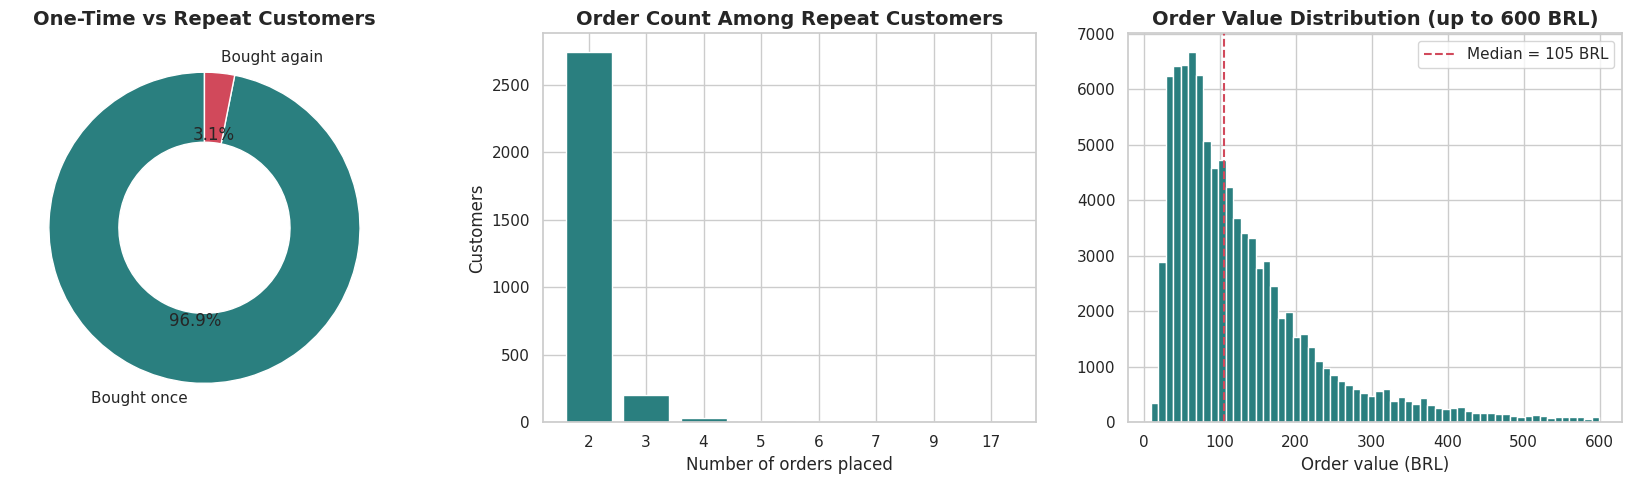

Repeat purchase rate: 3.12%
Average items per order: 1.14

Order value summary:
count   96,478.00
mean       159.83
std        218.79
min          9.59
25%         61.85
50%        105.28
75%        176.26
max     13,664.08


In [26]:
# Count orders per real person (customer_unique_id, NOT customer_id)
cust_orders = (
    orders_df.merge(customers_df, on="customer_id")
    .groupby("customer_unique_id")["order_id"].nunique()
)

repeat_rate = (cust_orders > 1).mean() * 100
order_values = delivered_df.groupby("order_id")["item_revenue"].sum()

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# (a) One-time buyers versus repeat buyers
split = pd.Series({
    "Bought once": (cust_orders == 1).sum(),
    "Bought again": (cust_orders > 1).sum(),
})
axes[0].pie(split.values, labels=split.index, autopct="%1.1f%%",
            colors=[MAIN, ACCENT], startangle=90, wedgeprops=dict(width=0.45))
axes[0].set_title("One-Time vs Repeat Customers")

# (b) How many orders repeat customers place
repeat_dist = cust_orders[cust_orders > 1].value_counts().sort_index().head(8)
axes[1].bar(repeat_dist.index.astype(str), repeat_dist.values, color=MAIN)
axes[1].set_title("Order Count Among Repeat Customers")
axes[1].set_xlabel("Number of orders placed")
axes[1].set_ylabel("Customers")

# (c) Distribution of order values
axes[2].hist(order_values[order_values <= 600], bins=60, color=MAIN, edgecolor="white")
axes[2].axvline(order_values.median(), color=ACCENT, linestyle="--",
                label=f"Median = {order_values.median():,.0f} BRL")
axes[2].set_title("Order Value Distribution (up to 600 BRL)")
axes[2].set_xlabel("Order value (BRL)")
axes[2].legend()

plt.tight_layout()
plt.show()

print(f"Repeat purchase rate: {repeat_rate:.2f}%")
print(f"Average items per order: {items_df.groupby('order_id')['order_item_id'].max().mean():.2f}")
print("\nOrder value summary:")
print(order_values.describe().to_string())

#### Customer insights

- Only about **3% of customers ever come back for a second order**. That is a very low
  retention level and it is the biggest weakness visible in this dataset.
- Baskets are small too: the **average order contains just 1.14 items**, so cross-selling
  is barely happening at checkout.
- Order values cluster below 150 BRL, with the median near **105 BRL**.

#### Business takeaway

- The business is running on a **constant flow of new customers**, which is the most
  expensive way to grow. A loyalty programme, post-purchase email flow or subscription
  option for repeat-use categories (health & beauty especially) would directly attack this.
- Because most orders hold a single item, **bundle offers and "frequently bought together"
  suggestions** have obvious room to lift average order value.

### 7.11 Correlation analysis

Now let us check which numeric measures actually move together.

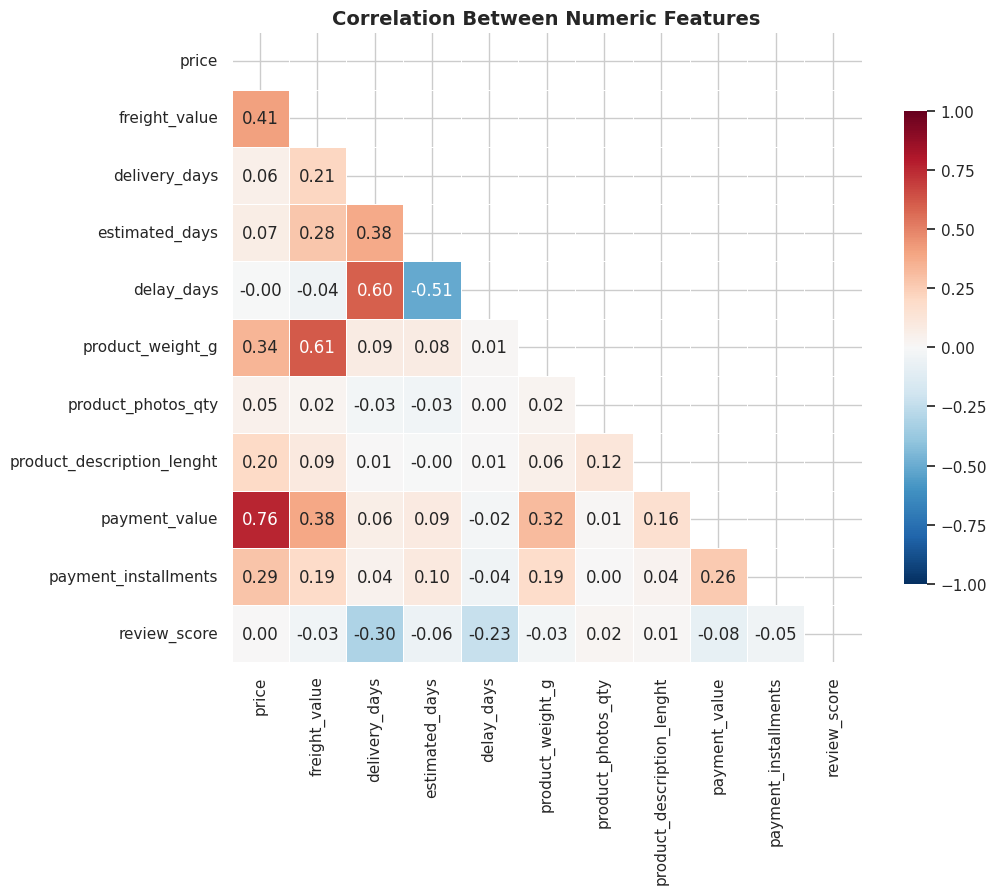

In [27]:
# Bring payment details down to one row per order
payment_by_order = (
    payments_df
    .groupby("order_id")
    .agg(payment_value=("payment_value", "sum"),
         payment_installments=("payment_installments", "max"))
    .reset_index()
)

# Pick the numeric columns that carry real business meaning, then attach
# payment info and the review score using order_id as the key.
corr_source = (
    delivered_df[["order_id", "price", "freight_value", "delivery_days", "estimated_days",
                  "delay_days", "product_weight_g", "product_photos_qty",
                  "product_description_lenght"]]
    .merge(payment_by_order, on="order_id", how="left")
    .merge(review_by_order, on="order_id", how="left")
    .drop(columns="order_id")
)

corr_matrix = corr_source.corr(numeric_only=True)

fig, ax = plt.subplots(figsize=(11, 9))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))     # hide the mirrored half
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.5,
            cbar_kws={"shrink": 0.75}, ax=ax)
ax.set_title("Correlation Between Numeric Features")
plt.tight_layout()
plt.show()

#### How to read this heatmap

- Values close to **+1** mean the two measures rise together, values close to **-1** mean one
  rises while the other falls, and values near **0** mean there is no straight-line link.
- **Product weight and freight value show the strongest positive link (about 0.61)** — heavier
  parcels simply cost more to ship, exactly as expected.
- **Price and freight are moderately linked (about 0.41)**, because expensive items also tend
  to be bigger.
- **Delivery days and review score are negatively linked**, which is the numeric version of
  the finding in section 7.8.
- Photo count and description length barely move with anything, so richer listings do **not**
  automatically mean higher prices or better ratings in this data.

> ⚠️ **Important reminder:** correlation only measures a straight-line relationship. It does
> not prove that one thing causes the other, and it will miss a curved relationship entirely.

---

## 8. RFM Customer Segmentation

RFM is a simple, widely used way to score customers on three things:

- **Recency** — how many days since their last purchase (smaller is better)
- **Frequency** — how many orders they have placed (bigger is better)
- **Monetary** — how much they have spent in total (bigger is better)

Each customer gets a 1-to-4 score on all three, and the three scores add up to a total
between 3 and 12 which we turn into a readable segment name.

In [28]:
# Work only with delivered orders, at the level of the real person
rfm_base = (
    delivered_df
    .groupby(["customer_unique_id", "order_id"])
    .agg(order_value=("item_revenue", "sum"),
         order_date=("order_purchase_timestamp", "first"))
    .reset_index()
)

# "Today" for this dataset = one day after the last purchase on record
snapshot_date = rfm_base["order_date"].max() + pd.Timedelta(days=1)
print("Snapshot date used:", snapshot_date.date())

rfm = rfm_base.groupby("customer_unique_id").agg(
    recency=("order_date", lambda d: (snapshot_date - d.max()).days),
    frequency=("order_id", "nunique"),
    monetary=("order_value", "sum"),
)

# --- Score each dimension from 1 (worst) to 4 (best) ---
# Recency is reversed: a small number of days is GOOD, so it gets the high score.
rfm["R_score"] = pd.qcut(rfm["recency"], q=4, labels=[4, 3, 2, 1]).astype(int)

# Frequency is mostly 1 for everyone, so ranking first avoids duplicate-edge errors
rfm["F_score"] = pd.qcut(rfm["frequency"].rank(method="first"), q=4, labels=[1, 2, 3, 4]).astype(int)
rfm["M_score"] = pd.qcut(rfm["monetary"], q=4, labels=[1, 2, 3, 4]).astype(int)

rfm["RFM_total"] = rfm[["R_score", "F_score", "M_score"]].sum(axis=1)

def label_segment(score):
    'Turn the total RFM score into a plain-English segment name.'
    if score >= 10:
        return "Champions"        # recent, frequent and high spending
    elif score >= 8:
        return "Loyal"            # solid, dependable customers
    elif score >= 6:
        return "Potential"        # worth nurturing
    elif score >= 4:
        return "At Risk"          # slipping away
    return "Lost"                 # basically gone

rfm["segment"] = rfm["RFM_total"].apply(label_segment)

rfm.head(10)

Snapshot date used: 2018-08-30


,recency,frequency,monetary,R_score,F_score,M_score,RFM_total,segment
customer_unique_id,,,,,,,,
0000366f3b9a7992bf8c76cfdf3221e2,112,1,141.90,4,1,3,8,Loyal
0000b849f77a49e4a4ce2b2a4ca5be3f,115,1,27.19,3,1,1,5,At Risk
0000f46a3911fa3c0805444483337064,537,1,86.22,1,1,2,4,At Risk
0000f6ccb0745a6a4b88665a16c9f078,321,1,43.62,2,1,1,4,At Risk
0004aac84e0df4da2b147fca70cf8255,288,1,196.89,2,1,4,7,Potential
0004bd2a26a76fe21f786e4fbd80607f,146,1,166.98,3,1,3,7,Potential
00050ab1314c0e55a6ca13cf7181fecf,132,1,35.38,3,1,1,5,At Risk
00053a61a98854899e70ed204dd4bafe,183,1,419.18,3,1,4,8,Loyal
0005e1862207bf6ccc02e4228effd9a0,543,1,150.12,1,1,3,5,At Risk


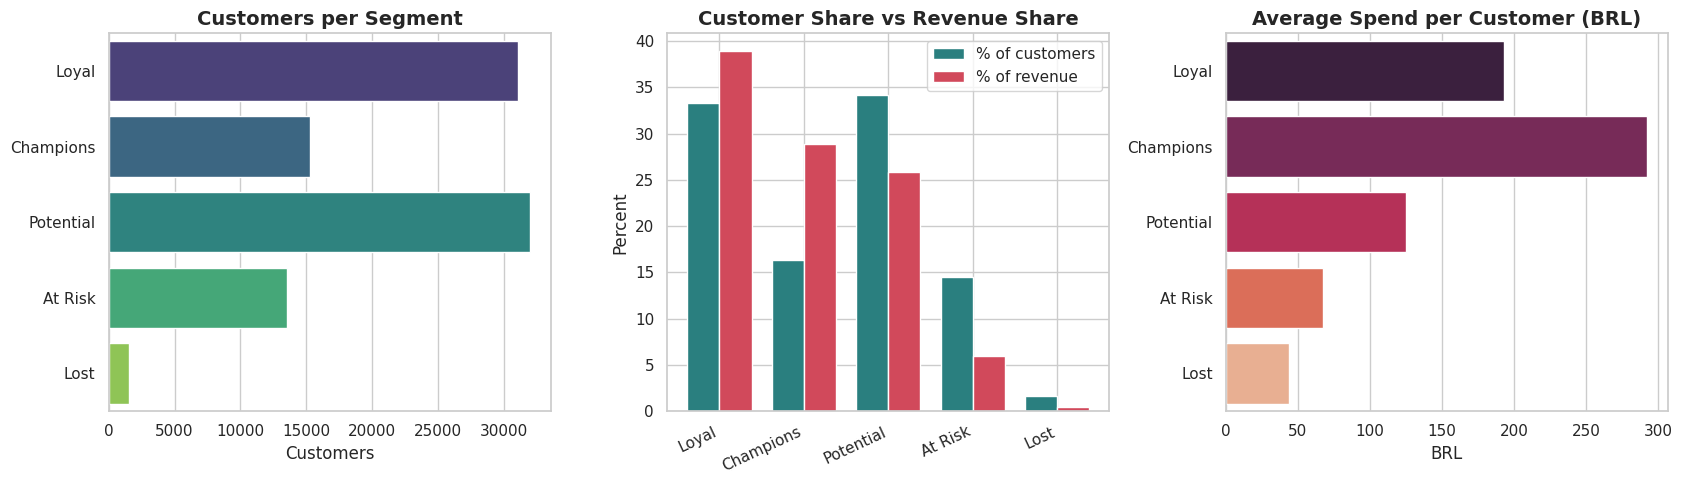

,customers,avg_recency_days,avg_frequency,avg_spend,total_spend,customer_share_pct,revenue_share_pct
segment,,,,,,,
Loyal,31100,195.35,1.03,192.86,"5,998,018.65",33.31,38.90
Champions,15247,115.07,1.14,291.99,"4,452,018.73",16.33,28.87
Potential,31944,274.59,1.00,124.98,"3,992,238.65",34.22,25.89
At Risk,13548,363.23,1.00,67.23,"910,830.15",14.51,5.91
Lost,1519,455.07,1.00,43.89,"66,667.57",1.63,0.43


In [29]:
# Summarise each segment
seg_summary = (
    rfm.groupby("segment")
    .agg(customers=("recency", "count"),
         avg_recency_days=("recency", "mean"),
         avg_frequency=("frequency", "mean"),
         avg_spend=("monetary", "mean"),
         total_spend=("monetary", "sum"))
    .sort_values("total_spend", ascending=False)
)
seg_summary["customer_share_pct"] = (seg_summary["customers"] / seg_summary["customers"].sum() * 100).round(2)
seg_summary["revenue_share_pct"] = (seg_summary["total_spend"] / seg_summary["total_spend"].sum() * 100).round(2)

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

order = seg_summary.index.tolist()

# (a) How many customers sit in each segment
sns.barplot(x=seg_summary["customers"], y=order, hue=order,
            palette=PALETTE, legend=False, ax=axes[0])
axes[0].set_title("Customers per Segment")
axes[0].set_xlabel("Customers")

# (b) Customer share vs revenue share, side by side
x = np.arange(len(order))
width = 0.38
axes[1].bar(x - width/2, seg_summary["customer_share_pct"], width, label="% of customers", color=MAIN)
axes[1].bar(x + width/2, seg_summary["revenue_share_pct"], width, label="% of revenue", color=ACCENT)
axes[1].set_xticks(x)
axes[1].set_xticklabels(order, rotation=25, ha="right")
axes[1].set_title("Customer Share vs Revenue Share")
axes[1].set_ylabel("Percent")
axes[1].legend()

# (c) Average spend per segment
sns.barplot(x=seg_summary["avg_spend"], y=order, hue=order,
            palette="rocket", legend=False, ax=axes[2])
axes[2].set_title("Average Spend per Customer (BRL)")
axes[2].set_xlabel("BRL")

plt.tight_layout()
plt.show()

seg_summary.round(2)

#### RFM insights

- **Champions are roughly 16% of customers but bring in close to 29% of revenue.** They are
  worth the most attention per head.
- **Loyal and Potential together form the bulk of the base** — this is the group where a
  small push can create the next batch of Champions.
- **At Risk and Lost customers spend far less on average** (well under 70 BRL) and have not
  bought in a long time. Chasing them hard is usually not worth the marketing cost.
- Because the repeat rate is only about 3%, the Frequency score does very little work in
  this particular dataset. Recency and Monetary carry most of the signal — worth
  remembering before presenting these segments as if all three mattered equally.

#### How each segment should be treated

- **Champions** — early access, loyalty perks, referral requests
- **Loyal** — bundle offers and gentle upselling into higher-value categories
- **Potential** — a second-purchase discount timed a few weeks after the first order
- **At Risk** — one well-timed win-back email, then stop spending
- **Lost** — leave them in the database, exclude from paid campaigns

---

## 9. Consolidated Insights

Everything discovered above, gathered in one place.

### 9.1 What is working well

- **Order completion is strong.** Roughly 97% of orders reach the customer, and
  cancellations stay under 1%.
- **Delivery beats the promise almost every time.** Only about 6.6% of orders are late, and
  the average parcel arrives around 12 days ahead of the quoted date.
- **Ratings are high overall**, with close to 77% of customers giving 4 or 5 stars.
- **Payments are frictionless.** Credit cards plus instalments let customers buy bigger
  baskets than they otherwise would.

### 9.2 What needs attention

- **Repeat purchase is close to non-existent** at about 3%. The business is buying growth
  through new customers every single month.
- **Everything is concentrated in one place.** São Paulo is about 42% of orders, the top 10%
  of sellers hold roughly two-thirds of revenue, and a handful of categories carry 80% of
  sales. Each of these is a single point of failure.
- **The slow tail of deliveries is expensive.** Orders taking more than a month average
  about 2.2 stars, and late orders lose roughly two stars compared to on-time ones.
- **Distant states pay twice** — higher freight and longer waits — which is exactly the
  combination that produces angry reviews.
- **Growth flattened in 2018** after a very steep 2017.

### 9.3 The five numbers worth remembering

| Metric | Value | Why it matters |
|--------|-------|----------------|
| Average order value | ~161 BRL | Sets the ceiling on marketing spend per order |
| Repeat purchase rate | ~3% | The clearest weakness in the whole business |
| Average delivery time | ~12 days | Double-digit waits are the norm, not the exception |
| Late delivery rate | ~6.6% | Small, but each late order costs about 2 stars |
| Top 10% of sellers | ~66% of revenue | Concentration risk that needs active management |

---

## 10. Recommendations

### 10.1 Fix the delivery tail first

- Identify the routes and states where delivery regularly crosses 20 days and negotiate
  those specific lanes with couriers, rather than trying to speed up everything at once.
- Set an internal alarm on any order crossing 20 days, and reach out to the customer
  **before** they leave the review. A proactive message often converts a 1-star into a 3-star.

### 10.2 Attack the repeat-purchase problem

- Trigger a second-purchase offer roughly two to three weeks after the first delivery, when
  the product experience is still fresh.
- Focus that offer on **health & beauty and housewares**, since those categories naturally
  get used up and re-bought.
- Add "frequently bought together" suggestions at checkout — with 1.14 items per order, even
  a small lift here moves revenue meaningfully.

### 10.3 Spread the concentration risk

- Recruit sellers in the **north and north-east** so parcels start closer to those customers.
- Build a key-account programme for the top 10% of sellers, and at the same time grow the
  next tier so the platform is not hostage to a small group.

### 10.4 Use the calendar

- Plan inventory, courier capacity and support staffing around **November**, which is the
  proven peak.
- Schedule campaigns for **Monday to Wednesday afternoons**, when buying intent is already at
  its highest.

### 10.5 Rethink the delivery promise

- The current 23-day quote is far more conservative than actual performance. Tightening it
  for south-eastern states could improve checkout conversion, as long as the buffer stays
  wide for distant regions where delays are real.

---

## 11. Limitations and Next Steps

### 11.1 Honest limitations of this analysis

- The data covers roughly **September 2016 to October 2018**, and both edge months are
  incomplete. Any trend read across those edges will be misleading.
- Customer IDs are anonymised, so we cannot bring in age, gender or income to explain
  behaviour.
- There is **no cost or margin data**, so "revenue" here is never the same thing as profit.
- Review text is written in Portuguese and mostly missing, so sentiment analysis on it was
  left out of scope.
- Correlation was measured, but **nothing in this notebook proves causation**. Slow delivery
  and low ratings move together; the causal claim would need a controlled test.

### 11.2 What could be built on top of this

- **Delivery-time prediction** using product weight, seller state and customer state, to
  quote a smarter date at checkout.
- **A bad-review early-warning model** that flags at-risk orders while they are still in
  transit.
- **Customer lifetime value modelling** once more history is available.
- **Text mining of the Portuguese review comments** to find out what specifically goes wrong
  in the 1-star cases.
- **A geospatial view** using the latitude and longitude in the geolocation table to map
  delivery performance across the country.

---

## 12. Conclusion

This project took nine separate raw files and turned them into a single, connected picture
of a marketplace.

The strongest and most actionable finding is the link between **delivery speed and customer
satisfaction**: a late parcel costs roughly two stars, and a parcel taking over a month
collapses the rating to barely two stars overall. Logistics, not merchandising, is the main
lever on happiness here.

The largest opportunity is the **3% repeat-purchase rate**. The platform proved it can
acquire customers at scale during 2017; converting even a small share of those buyers into
returning customers would change the growth picture without spending more on acquisition.

And the biggest risk is **concentration** — in one state, in a small group of sellers, and in
a handful of categories. Each of those is fine while things go well and dangerous when they
do not.

---

*Analysis carried out with pandas, numpy, matplotlib and seaborn.*